# Does Resting-State EEG Add Value Beyond Neuropsychological Assessment in FASD and ADHD? A Multimodal Machine Learning Study

DOI: to be added upon publication

### About

Full analysis pipeline of the study: resting-state EEG preprocessing, feature extraction, and L1-SVM classification of FASD vs ADHD (20 + 20 children) with nested leave-one-subject-out cross-validation. EEG-only models (single-family and paired-family) are compared with a neuropsychological baseline (FSIQ and Stroop-WC) and with multimodal models, followed by age and medication robustness checks.

### How to run

1. Set `BASE_DIR` in Section 1 to work from the repository root.
2. Run the sections in order. Heavy steps are controlled by `RUN_*` flags (default `False`) and load saved outputs instead; each section ends with an audit table.
3. Set a flag to `True` only to recompute that step. All random procedures use `RANDOM_SEED = 42`.
4. Install dependencies with `pip install -r requirements.txt`.

Data are not public for ethical reasons; anonymised feature matrices are available on request from the corresponding author.

## 1. Setup, paths and base functions

In [1]:
# -----------------------------------------------------------------------------
# Imports
# -----------------------------------------------------------------------------
import gc
import os
import re
import shutil
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, HTML
from tqdm.auto import tqdm

import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns

import mne
from mne.time_frequency import psd_array_multitaper
from mne_icalabel import label_components
from autoreject import AutoReject, Ransac
import antropy as ant

from scipy import stats
from scipy.special import expit
from scipy.stats import (
    chi2_contingency,
    false_discovery_control,
    fisher_exact,
    mannwhitneyu,
    pearsonr,
    shapiro,
    spearmanr,
    ttest_ind,
)
from statsmodels.stats.multitest import multipletests

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    auc as sk_auc,
    confusion_matrix,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, LinearSVR

# -----------------------------------------------------------------------------
# Global settings
# -----------------------------------------------------------------------------
%matplotlib inline
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)
mne.set_log_level("WARNING")

sns.set_theme(style="white")
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = "Segoe UI" if "Segoe UI" in _fonts else "DejaVu Sans"

RANDOM_SEED = 42
CLINICAL_GROUPS = ["FASD", "ADHD"]
GROUP_PALETTE = {"FASD": "#1B4F72", "ADHD": "#2E86C1", "F": "#1B4F72", "M": "#2E86C1"}

# -----------------------------------------------------------------------------
# Paths
# -----------------------------------------------------------------------------
# Base directory: set to Path(".") for a generic relative path (e.g. on GitHub).
BASE_DIR = Path(r"C:\Users\Usuario\FASD_ADHD")

# Input data
PATH_RAW          = BASE_DIR / "raw"                # raw/FASD/*.vhdr, raw/ADHD/*.vhdr
PATH_DEMOGRAPHICS = BASE_DIR / "demographics.xlsx"
PATH_NP_SCORES    = BASE_DIR / "np_scores.xlsx"

# Preprocessing and epoching
PATH_PREPROC  = BASE_DIR / "preprocessed"
PATH_EPOCHS   = BASE_DIR / "epochs"
PATH_BALANCED = BASE_DIR / "balanced_epochs"

# Cohort-synchronized tables
PATH_DEMOGRAPHICS_CLEAN    = BASE_DIR / "demographics_cleaned.xlsx"
PATH_NP_SCORES_CLEAN       = BASE_DIR / "np_scores_cleaned.xlsx"
PATH_DEMOGRAPHICS_BALANCED = BASE_DIR / "demographics_balanced.xlsx"
PATH_NP_SCORES_BALANCED    = BASE_DIR / "np_scores_balanced.xlsx"

# Feature matrices and model outputs
PATH_EEG_FEATURES  = BASE_DIR / "eeg_features"
PATH_EEG_MATRIX    = PATH_EEG_FEATURES / "df_eeg.xlsx"
PATH_SINGLE_FAMILY = PATH_EEG_FEATURES / "single_family_eeg"
PATH_PAIRED_FAMILY = PATH_EEG_FEATURES / "paired_family_eeg"
PATH_MULTIMODAL    = PATH_EEG_FEATURES / "Multimodal"
PATH_NP_FEATURES   = BASE_DIR / "np_features"
PATH_NP_MASTER     = BASE_DIR / "df_np_master.xlsx"

# Downstream analyses
PATH_DEMOGRAPHIC_TABLE = BASE_DIR / "demographic_summary.xlsx"
PATH_RESULTS     = BASE_DIR / "Results"
PATH_AGE_AUDIT   = PATH_RESULTS / "Age audit"
PATH_COMPARISONS = PATH_RESULTS / "Statistical_Comparisons"
PATH_MEDICATION  = BASE_DIR / "results_medication"

for base in (PATH_PREPROC, PATH_EPOCHS, PATH_BALANCED):
    for group in CLINICAL_GROUPS:
        (base / group).mkdir(parents=True, exist_ok=True)

for folder in (PATH_SINGLE_FAMILY, PATH_PAIRED_FAMILY, PATH_MULTIMODAL, PATH_NP_FEATURES,
               PATH_RESULTS, PATH_AGE_AUDIT, PATH_COMPARISONS, PATH_MEDICATION):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Base directory: {BASE_DIR.resolve()}")

# -----------------------------------------------------------------------------
# Base functions
# -----------------------------------------------------------------------------
_REPORT_CSS = """
<style>
    table { border-collapse: collapse; width: 85%; font-family: 'Segoe UI', sans-serif; font-size: 12px; margin: 15px 0; border-bottom: 2px solid #1B4F72; }
    th { background-color: #1B4F72; color: white; padding: 10px 15px; text-align: center; font-weight: 600; text-transform: uppercase; border: 1px solid #fff; }
    td { padding: 8px 15px; text-align: center; border-bottom: 1px solid #EEE; }
    tr:nth-child(even) { background-color: #FAFAFA; }
    tr:hover { background-color: #F4F7F9; transition: 0.3s; }
    .report-title { color: #1B4F72; font-weight: bold; font-size: 16px; margin: 20px 0 10px 0; border-left: 5px solid #1B4F72; padding-left: 15px; text-transform: none; }
</style>
"""


def report_style(df, title, index=False):
    """Display a DataFrame as a styled HTML table with a title."""
    display(HTML(
        f"{_REPORT_CSS}<div class='report-title'>{title}</div>"
        f"{df.to_html(index=index, border=0, classes='report-table')}"
    ))


def fmt_p(p):
    """Format a p-value for tables."""
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

Base directory: C:\Users\Usuario\FASD_ADHD


## 2. EEG preprocessing

In [2]:
# -----------------------------------------------------------------------------
# Parameters
# -----------------------------------------------------------------------------
params = {
    "low_freq": 0.5,              # High-pass cutoff (Hz)
    "high_freq": 50.0,            # Low-pass cutoff (Hz)
    "ica_l_freq": 1.0,            # High-pass cutoff used only for ICA fitting (Hz)
    "epoch_dur": 2.0,             # Epoch length (s)
    "ica_prob_threshold": 0.90,   # ICLabel probability threshold
    "ransac_min_corr": 0.75,      # RANSAC minimum spatial correlation
    "mag_thresh": 300e-6,         # Peak-to-peak rejection threshold (V)
}

EC_TRIGGERS = {"start": "Stimulus/S 96", "end": "Stimulus/S 97"}

EXPECTED_EEG_CHANNELS = [
    "Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8", "FC5", "FC1", "FC2", "FC6",
    "T7", "C3", "Cz", "C4", "T8", "CP5", "CP1", "CP2", "CP6",
    "P7", "P3", "Pz", "P4", "P8", "O1", "Oz", "O2",
]

REPORT_COLUMNS = [
    "Subject", "Group", "Phase", "Phase Duration", "Global Bad Channels",
    "ICA Comp. Removed", "ICLabel", "Rejected Epochs", "Repaired Epochs",
    "Interpol. Density", "Final Epoch Count", "Data Retained %",
]


# -----------------------------------------------------------------------------
# Preprocessing functions
# -----------------------------------------------------------------------------
def load_and_setup_data(file_path):
    """Load a BrainVision recording, standardize channel names and set the montage."""
    raw = mne.io.read_raw_brainvision(file_path, preload=True, verbose=False)

    channel_mapping = {"FZ": "Fz", "CZ": "Cz", "PZ": "Pz", "OZ": "Oz"}
    raw.rename_channels({k: v for k, v in channel_mapping.items() if k in raw.ch_names})

    eog_map = {ch: "eog" for ch in ["VEOU", "HEOR"] if ch in raw.ch_names}
    if eog_map:
        raw.set_channel_types(eog_map)

    raw.set_montage("standard_1020", match_case=False, on_missing="warn")
    return raw


def apply_initial_filtering(raw, params):
    """Apply a 50 Hz notch filter and a zero-phase FIR band-pass filter."""
    raw.notch_filter(freqs=50, fir_design="firwin", verbose=False)
    raw.filter(
        l_freq=params["low_freq"], h_freq=params["high_freq"],
        method="fir", phase="zero-double", verbose=False,
    )
    return raw


def identify_bad_channels_ransac(raw, params):
    """Flag spatially inconsistent channels with RANSAC; interpolation is deferred until after ICA."""
    temp_epochs = mne.make_fixed_length_epochs(raw, duration=3.0, preload=True, verbose=False)

    ransac = Ransac(
        verbose=False, picks="eeg", n_jobs=1, random_state=RANDOM_SEED,
        min_corr=params["ransac_min_corr"],
    )
    ransac.fit(temp_epochs)

    raw.info["bads"] = ransac.bad_chs_
    return raw, raw.info["bads"].copy()


def run_ica_decomposition(raw, params):
    """Remove eye-blink and muscle components (ICLabel), with an EOG-correlation fallback for blinks."""
    raw_for_ica = raw.copy().filter(l_freq=params["ica_l_freq"], h_freq=None, verbose=False)
    raw_for_ica.set_eeg_reference("average", projection=False, verbose=False)

    n_components = mne.compute_rank(raw_for_ica, rank="info")["eeg"] - 1
    ica = mne.preprocessing.ICA(
        n_components=n_components, method="infomax",
        fit_params=dict(extended=True), random_state=RANDOM_SEED,
    )
    ica.fit(raw_for_ica, picks="eeg", verbose=False)

    ic_labels = label_components(raw_for_ica, ica, method="iclabel")
    labels = ic_labels["labels"]
    probas = [p.max() for p in ic_labels["y_pred_proba"]]

    ica.exclude = [
        i for i, (label, p) in enumerate(zip(labels, probas))
        if label in ["eye blink", "muscle artifact"] and p >= params["ica_prob_threshold"]
    ]
    ic_details = [f"{labels[i]} ({probas[i] * 100:.1f}%)" for i in ica.exclude]

    # EOG fallback when no blink component passed the ICLabel threshold
    has_blink = any(labels[i] == "eye blink" for i in ica.exclude)
    if not has_blink:
        eog_chans = [ch for ch in ["VEOU", "HEOR"] if ch in raw.ch_names]
        if eog_chans:
            eog_inds, _ = ica.find_bads_eog(raw_for_ica, ch_name=eog_chans, threshold=3.0, verbose=False)
            for idx in eog_inds:
                if idx not in ica.exclude:
                    ica.exclude.append(idx)
                    ic_details.append("eye blink (eog)")

    ic_string = ", ".join(ic_details) if ic_details else "None"
    return ica.apply(raw.copy(), verbose=False), ica, ic_string


def apply_autoreject_repair(raw_clean, params, n_ransac_bads=0):
    """Epoch the signal, repair/reject epochs with AutoReject and compute the interpolation density."""
    events = mne.make_fixed_length_events(raw_clean, duration=params["epoch_dur"])
    n_theoretical = len(events)
    n_channels = len(raw_clean.ch_names)

    epochs = mne.Epochs(
        raw_clean, events, tmin=0, tmax=params["epoch_dur"] - (1 / raw_clean.info["sfreq"]),
        baseline=None, detrend=1, preload=True, verbose=False,
    )

    ar = AutoReject(n_interpolate=[1, 2, 4], random_state=RANDOM_SEED, verbose=False)
    epochs_clean, reject_log = ar.fit_transform(epochs, return_log=True)
    ar_rejected = sum(reject_log.bad_epochs)

    epochs_clean.drop_bad(reject=dict(eeg=params["mag_thresh"]), verbose=False)
    final_epochs_count = len(epochs_clean)
    mag_dropped = n_theoretical - ar_rejected - final_epochs_count

    local_interpolations = np.sum(reject_log.labels == 1)
    global_interpolations = n_ransac_bads * len(epochs)
    total_data_units = len(epochs) * n_channels

    epochs_clean.set_eeg_reference("average", projection=False, verbose=False)

    stats_dict = {
        "theoretical": n_theoretical,
        "total_rejected": mag_dropped + ar_rejected,
        "epochs_repaired": np.any(reject_log.labels == 1, axis=1).sum(),
        "interp_density": ((local_interpolations + global_interpolations) / total_data_units) * 100
        if total_data_units > 0 else 0,
        "final": final_epochs_count,
    }
    return epochs_clean, stats_dict


def preprocess_subject(file_path, group, params, ec_triggers):
    """Run the eyes-closed pipeline for one recording; return (epochs, report_row), or (None, None) if triggers are missing."""
    subject_id = file_path.stem

    raw = apply_initial_filtering(load_and_setup_data(str(file_path)), params)
    events, event_id = mne.events_from_annotations(raw, verbose=False)
    id_map = {k.strip(): v for k, v in event_id.items()}

    start_label, end_label = ec_triggers["start"].strip(), ec_triggers["end"].strip()
    if start_label not in id_map or end_label not in id_map:
        print(f"Warning: eyes-closed triggers missing for {subject_id}")
        return None, None

    t_start = events[events[:, 2] == id_map[start_label]][0, 0] / raw.info["sfreq"]
    t_end = events[events[:, 2] == id_map[end_label]][0, 0] / raw.info["sfreq"]

    raw_seg = raw.copy().crop(tmin=t_start, tmax=t_end)
    raw_seg, ransac_bads = identify_bad_channels_ransac(raw_seg, params)
    raw_clean, ica, ic_string = run_ica_decomposition(raw_seg, params)

    if raw_clean.info["bads"]:
        raw_clean.interpolate_bads(reset_bads=True)

    epochs, ep = apply_autoreject_repair(raw_clean, params, n_ransac_bads=len(ransac_bads))

    row = {
        "Subject": subject_id,
        "Group": group,
        "Phase": "CE",
        "Phase Duration": f"{t_end - t_start:.2f}s",
        "Global Bad Channels": ", ".join(ransac_bads) if ransac_bads else "None",
        "ICA Comp. Removed": len(ica.exclude),
        "ICLabel": ic_string,
        "Rejected Epochs": f"{ep['total_rejected']}/{ep['theoretical']}",
        "Repaired Epochs": f"{ep['epochs_repaired']}/{ep['theoretical']}",
        "Interpol. Density": f"{round(ep['interp_density'], 2)}%",
        "Final Epoch Count": f"{ep['final']}/{ep['theoretical']}",
        "Data Retained %": f"{round((ep['final'] / ep['theoretical']) * 100, 1)}%",
    }
    return epochs, row


def preproc_pipeline(path_raw_base, path_preproc_base, groups, params, ec_triggers):
    """Preprocess every recording of every group and save the epochs and a per-group report."""
    all_rows = []

    for group in groups:
        path_group_preproc = path_preproc_base / group
        path_group_preproc.mkdir(parents=True, exist_ok=True)
        group_rows = []

        for file_path in sorted((path_raw_base / group).glob("*.vhdr")):
            subject_id = file_path.stem
            try:
                print(f"Processing {subject_id}")
                epochs, row = preprocess_subject(file_path, group, params, ec_triggers)
                if epochs is None:
                    continue
                epochs.save(path_group_preproc / f"{subject_id}_ce-epo.fif", overwrite=True, verbose=False)
                group_rows.append(row)
                gc.collect()
            except Exception as e:
                print(f"Error: {subject_id} failed: {e}")

        report_path = path_group_preproc / f"{group}_Preprocessing_Report.xlsx"
        pd.DataFrame(group_rows).to_excel(report_path, index=False)
        print(f"Group report saved: {report_path.name}")
        all_rows.extend(group_rows)

    return pd.DataFrame(all_rows)


def show_preprocessing_reports(path_preproc_base, groups):
    """Display the saved preprocessing report of each group."""
    for group in groups:
        df = pd.read_excel(path_preproc_base / group / f"{group}_Preprocessing_Report.xlsx", keep_default_na=False)
        report_style(df, f"{group} Preprocessing Report")

In [3]:
RUN_PREPROCESSING = False  # True re-runs the full pipeline (slow) and overwrites the saved outputs

if RUN_PREPROCESSING:
    all_stats_df = preproc_pipeline(
        path_raw_base=PATH_RAW,
        path_preproc_base=PATH_PREPROC,
        groups=CLINICAL_GROUPS,
        params=params,
        ec_triggers=EC_TRIGGERS,
    )

show_preprocessing_reports(PATH_PREPROC, CLINICAL_GROUPS)

Subject,Group,Phase,Phase Duration,Global Bad Channels,ICA Comp. Removed,ICLabel,Rejected Epochs,Repaired Epochs,Interpol. Density,Final Epoch Count,Data Retained %
sub-01_fasd,FASD,CE,163.19s,None,3,"eye blink (98.9%), eye blink (99.7%), muscle artifact (96.7%)",17/81,27/81,12.76%,64/81,79.0%
sub-02_fasd,FASD,CE,157.17s,None,3,"eye blink (99.2%), eye blink (99.6%), eye blink (91.8%)",9/78,29/78,7.48%,69/78,88.5%
sub-03_fasd,FASD,CE,140.31s,None,3,"eye blink (99.4%), eye blink (99.9%), eye blink (99.3%)",11/70,34/70,16.95%,59/70,84.3%
sub-04_fasd,FASD,CE,120.44s,None,2,"eye blink (99.2%), eye blink (99.1%)",1/60,10/60,3.56%,59/60,98.3%
sub-05_fasd,FASD,CE,159.14s,None,4,"eye blink (99.0%), eye blink (90.8%), eye blink (93.1%), eye blink (98.4%)",25/79,28/79,22.53%,54/79,68.4%
sub-06_fasd,FASD,CE,160.98s,None,2,"eye blink (99.9%), eye blink (99.7%)",2/80,20/80,2.12%,78/80,97.5%
sub-07_fasd,FASD,CE,162.04s,None,3,"eye blink (99.3%), eye blink (99.2%), muscle artifact (97.3%)",0/81,16/81,3.42%,81/81,100.0%
sub-08_fasd,FASD,CE,155.26s,None,3,"eye blink (98.9%), eye blink (99.0%), eye blink (97.1%)",1/77,8/77,1.0%,76/77,98.7%
sub-09_fasd,FASD,CE,163.09s,None,2,"eye blink (99.7%), eye blink (98.2%)",10/81,56/81,21.32%,71/81,87.7%
sub-10_fasd,FASD,CE,169.09s,None,3,"eye blink (98.9%), eye blink (98.7%), eye blink (94.3%)",15/84,35/84,12.06%,69/84,82.1%


Subject,Group,Phase,Phase Duration,Global Bad Channels,ICA Comp. Removed,ICLabel,Rejected Epochs,Repaired Epochs,Interpol. Density,Final Epoch Count,Data Retained %
sub-01_adhd,ADHD,CE,157.07s,None,2,"eye blink (98.6%), eye blink (99.4%)",12/78,25/78,9.02%,66/78,84.6%
sub-02_adhd,ADHD,CE,138.08s,None,3,"eye blink (98.2%), eye blink (99.8%), muscle artifact (95.4%)",6/69,23/69,10.72%,63/69,91.3%
sub-03_adhd,ADHD,CE,149.66s,None,2,"eye blink (99.7%), eye blink (99.2%)",10/74,26/74,12.3%,64/74,86.5%
sub-04_adhd,ADHD,CE,157.52s,None,6,"eye blink (99.7%), eye blink (100.0%), muscle artifact (99.4%), muscle artifact (99.7%), eye blink (92.4%), eye blink (92.3%)",11/78,17/78,7.35%,67/78,85.9%
sub-05_adhd,ADHD,CE,156.04s,None,2,"eye blink (99.1%), eye blink (99.9%)",42/78,67/78,35.04%,36/78,46.2%
sub-06_adhd,ADHD,CE,151.29s,None,2,"eye blink (eog), eye blink (eog)",5/75,32/75,9.82%,70/75,93.3%
sub-07_adhd,ADHD,CE,138.41s,None,4,"eye blink (93.9%), eye blink (99.7%), muscle artifact (98.3%), muscle artifact (95.3%)",14/69,47/69,21.45%,55/69,79.7%
sub-08_adhd,ADHD,CE,119.22s,None,2,"eye blink (96.6%), eye blink (94.1%)",20/59,33/59,24.97%,39/59,66.1%
sub-09_adhd,ADHD,CE,164.19s,None,2,"eye blink (98.5%), eye blink (99.8%)",34/82,40/82,14.84%,48/82,58.5%
sub-10_adhd,ADHD,CE,167.50s,None,2,"eye blink (99.0%), eye blink (99.4%)",28/83,34/83,19.64%,55/83,66.3%


## 3. Quality control and final cohort

In [4]:
qc_params = {
    "min_retention": 50.0,   # Minimum % of epochs retained after rejection
    "max_density": 30.0,     # Maximum % of signal that can be interpolated
    "min_duration": 40.0,    # Minimum clean signal duration (s)
    "epoch_length": 2.0,     # Epoch length (s)
}


def load_preprocessing_reports(path_preproc_base, groups):
    """Merge the per-group preprocessing reports and add numeric QC columns."""
    frames = [
        pd.read_excel(path_preproc_base / g / f"{g}_Preprocessing_Report.xlsx", keep_default_na=False)
        for g in groups
    ]
    df = pd.concat(frames, ignore_index=True)

    df["Duration_s"] = df["Phase Duration"].str.rstrip("s").astype(float)
    df["Retention_Num"] = df["Data Retained %"].str.rstrip("%").astype(float)
    df["Density_Num"] = df["Interpol. Density"].str.rstrip("%").astype(float)
    df["ICA_Count"] = df["ICA Comp. Removed"].astype(int)
    df["Final_Count"] = df["Final Epoch Count"].str.split("/").str[0].astype(int)
    df["Total_Clean_Seconds"] = df["Final_Count"] * qc_params["epoch_length"]
    return df


def quality_summary_table(df, groups):
    """Mean ± SD of the main QC metrics by group and for the whole initial sample."""
    def mean_sd(values):
        return f"{values.mean():.2f} ± {values.std():.2f}"

    rows = []
    for label, sub in [(g, df[df["Group"] == g]) for g in groups] + [("All", df)]:
        rows.append({
            "Group": label,
            "N": len(sub),
            "Recording Duration (s)": mean_sd(sub["Duration_s"]),
            "Data Retention (%)": mean_sd(sub["Retention_Num"]),
            "Interpolation Density (%)": mean_sd(sub["Density_Num"]),
            "ICA Components Removed": mean_sd(sub["ICA_Count"]),
        })
    return pd.DataFrame(rows)


def compare_groups(df, metric_col, label, groups=("FASD", "ADHD")):
    """Compare one QC metric between groups: Student/Welch t-test if both groups are normal, else Mann-Whitney U."""
    x = df.loc[df["Group"] == groups[0], metric_col].dropna()
    y = df.loc[df["Group"] == groups[1], metric_col].dropna()
    n1, n2 = len(x), len(y)

    is_normal = shapiro(x)[1] > 0.05 and shapiro(y)[1] > 0.05
    if is_normal:
        equal_var = stats.levene(x, y)[1] > 0.05
        t_stat, p_val = ttest_ind(x, y, equal_var=equal_var)
        dof = n1 + n2 - 2
        pooled_sd = np.sqrt(((n1 - 1) * x.var() + (n2 - 1) * y.var()) / dof)
        test = "Student's t-test" if equal_var else "Welch's t-test"
        statistic = f"t({dof}) = {t_stat:.2f}"
        effect = f"d = {(x.mean() - y.mean()) / pooled_sd:.2f}"
    else:
        u_stat, p_val = mannwhitneyu(x, y, alternative="two-sided")
        test = "Mann-Whitney U"
        statistic = f"U = {u_stat:.2f}"
        effect = f"r = {2 * u_stat / (n1 * n2) - 1:.2f}"

    return {
        "Metric": label,
        groups[0]: f"{x.mean():.2f} ± {x.std():.2f}",
        groups[1]: f"{y.mean():.2f} ± {y.std():.2f}",
        "Test": test,
        "Statistic": statistic,
        "p-value": fmt_p(p_val),
        "Effect size": effect,
    }


df_master = load_preprocessing_reports(PATH_PREPROC, CLINICAL_GROUPS)

report_style(quality_summary_table(df_master, CLINICAL_GROUPS), "Data Integrity and Preprocessing Metrics")
report_style(
    pd.DataFrame([
        compare_groups(df_master, "ICA_Count", "ICA components removed"),
        compare_groups(df_master, "Density_Num", "Interpolation density (%)"),
    ]),
    "Group Comparison of Preprocessing Metrics",
)

Group,N,Recording Duration (s),Data Retention (%),Interpolation Density (%),ICA Components Removed
FASD,20,152.43 ± 13.24,87.88 ± 10.71,10.46 ± 6.84,2.60 ± 0.68
ADHD,21,151.21 ± 9.99,78.50 ± 14.34,14.31 ± 8.19,2.48 ± 0.98
All,41,151.80 ± 11.42,83.08 ± 13.41,12.43 ± 7.71,2.54 ± 0.84


Metric,FASD,ADHD,Test,Statistic,p-value,Effect size
ICA components removed,2.60 ± 0.68,2.48 ± 0.98,Mann-Whitney U,U = 259.00,0.156,r = 0.23
Interpolation density (%),10.46 ± 6.84,14.31 ± 8.19,Student's t-test,t(39) = -1.63,0.111,d = -0.51


In [5]:
def get_exclusion_reason(row, qc_params):
    """List the QC criteria a subject failed."""
    reasons = []
    if row["Retention_Num"] < qc_params["min_retention"]:
        reasons.append("Low Retention")
    if row["Density_Num"] > qc_params["max_density"]:
        reasons.append("High Interpolation")
    if row["Total_Clean_Seconds"] < qc_params["min_duration"]:
        reasons.append("Insufficient Duration")
    return " + ".join(reasons)


exclusion_mask = (
    (df_master["Retention_Num"] < qc_params["min_retention"])
    | (df_master["Density_Num"] > qc_params["max_density"])
    | (df_master["Total_Clean_Seconds"] < qc_params["min_duration"])
)

df_excluded = df_master[exclusion_mask].copy()
df_final_clean = df_master.drop(df_excluded.index).reset_index(drop=True)

if df_excluded.empty:
    print("All recordings met the quality criteria; no subjects were excluded.")
else:
    df_excluded["Reason for Exclusion"] = df_excluded.apply(get_exclusion_reason, qc_params=qc_params, axis=1)
    report_style(
        df_excluded[["Subject", "Group", "Retention_Num", "Density_Num", "Total_Clean_Seconds", "Reason for Exclusion"]]
        .rename(columns={"Retention_Num": "Retention (%)", "Density_Num": "Interpolation (%)",
                         "Total_Clean_Seconds": "Duration (s)"}),
        "Quality Control Exclusion Report",
    )

attrition = pd.DataFrame([
    {
        "Group": g,
        "Original (N)": (df_master["Group"] == g).sum(),
        "Excluded": (df_excluded["Group"] == g).sum(),
        "Final (n)": (df_final_clean["Group"] == g).sum(),
        "Retention Rate": f"{(df_final_clean['Group'] == g).sum() / (df_master['Group'] == g).sum() * 100:.1f}%",
    }
    for g in CLINICAL_GROUPS
])
report_style(attrition, "Sample Size Attrition")

# Synchronize demographics and neuropsychological scores with the final cohort
valid_subjects = df_final_clean["Subject"].unique()

df_demo_raw = pd.read_excel(PATH_DEMOGRAPHICS).rename(columns={"ID": "Subject"})
df_np_raw = pd.read_excel(PATH_NP_SCORES).rename(columns={"ID": "Subject"})
df_demo_cleaned = df_demo_raw[df_demo_raw["Subject"].isin(valid_subjects)].copy()
df_np_cleaned = df_np_raw[df_np_raw["Subject"].isin(valid_subjects)].copy()

df_demo_cleaned.to_excel(PATH_DEMOGRAPHICS_CLEAN, index=False)
df_np_cleaned.to_excel(PATH_NP_SCORES_CLEAN, index=False)

is_synchronized = (set(valid_subjects) == set(df_demo_cleaned["Subject"]) == set(df_np_cleaned["Subject"])
                   and len(valid_subjects) == len(df_demo_cleaned) == len(df_np_cleaned))
report_style(
    pd.DataFrame([{
        "EEG Records": len(valid_subjects),
        "Demographics Records": len(df_demo_cleaned),
        "NP Scores Records": len(df_np_cleaned),
        "Synchronization Status": "Complete (1:1:1 match)" if is_synchronized else "MISMATCH",
    }]),
    "Database Synchronization Summary",
)

Subject,Group,Retention (%),Interpolation (%),Duration (s),Reason for Exclusion
sub-05_adhd,ADHD,46.2,35.04,72.0,Low Retention + High Interpolation


Group,Original (N),Excluded,Final (n),Retention Rate
FASD,20,0,20,100.0%
ADHD,21,1,20,95.2%


EEG Records,Demographics Records,NP Scores Records,Synchronization Status
40,40,40,Complete (1:1:1 match)


In [6]:
STIMULANTS = ["concerta", "medikinet", "rubifen", "elvanse", "methylphenidate", "lisdexamfetamine"]
NON_STIMULANTS = ["atomoxetina", "atomoxetine", "intuniv", "guanfacine", "catapresan", "clonidine"]
ANTIPSYCHOTICS = ["risperidal", "risperidona", "risperidone"]
NON_PSYCHOTROPIC = ["eutirox", "tardyferon", "levothyroxine", "iron"]


def parse_medications(entry):
    """Classify a free-text medication entry into pharmacological families."""
    empty = {"is_medicated": False, "has_stimulant": False, "has_non_stimulant": False,
             "has_antipsychotic": False, "is_polypharmacy": False}
    if pd.isna(entry) or str(entry).strip() in ["-", "", "nan", "None"]:
        return empty

    items = [i.strip().lower() for i in str(entry).split(",")]
    psychotropic = [i for i in items if not any(m in i for m in NON_PSYCHOTROPIC)]
    return {
        "is_medicated": len(psychotropic) >= 1,
        "has_stimulant": any(any(s in i for s in STIMULANTS) for i in items),
        "has_non_stimulant": any(any(s in i for s in NON_STIMULANTS) for i in items),
        "has_antipsychotic": any(any(s in i for s in ANTIPSYCHOTICS) for i in items),
        "is_polypharmacy": len(psychotropic) >= 2,
    }


def cramers_v_2x2(table):
    """Cramér's V (phi) for a 2x2 contingency table."""
    (a, b), (c, d) = table
    denom = (a + b) * (c + d) * (a + c) * (b + d)
    return float(np.sqrt((a * d - b * c) ** 2 / denom)) if denom else 0.0


def n_pct(n, total):
    """Format a count with its percentage, dropping decimals for whole percentages."""
    pct = round(n / total * 100, 1)
    return f"{n} ({pct:.1f}%)" if pct % 1 else f"{n} ({int(pct)}%)"


def build_demographic_table(df, groups=("FASD", "ADHD")):
    """Descriptive and inferential comparison of demographic and clinical characteristics."""
    df = df.copy()
    labels = {0: "FASD", 1: "ADHD", "0": "FASD", "1": "ADHD", "FASD": "FASD", "ADHD": "ADHD"}
    df["Group_Label"] = df["Group"].map(labels)
    df["Sex"] = df["Sex"].astype(str).str.upper().str.strip()
    df = pd.concat([df, df["Medication"].apply(parse_medications).apply(pd.Series)], axis=1)

    g1, g2 = (df[df["Group_Label"] == g] for g in groups)
    n1, n2 = len(g1), len(g2)
    indent = "\u00a0\u00a0"
    rows = []

    def add(label, v1, v2, statistic="-", p="-", effect="-", sub=False):
        rows.append({"Characteristic": (indent if sub else "") + label, groups[0]: v1, groups[1]: v2,
                     "Statistic": statistic, "p-value": p, "Effect size": effect})

    def add_header(label):
        add(label, "", "", "", "", "")

    def add_binary(label, pos1, pos2, test_stats=True):
        """Add a binary category row; Fisher's exact test and V are reported on this row."""
        if test_stats:
            table = [[pos1, n1 - pos1], [pos2, n2 - pos2]]
            p = stats.fisher_exact(table)[1]
            add(label, n_pct(pos1, n1), n_pct(pos2, n2), "Fisher's exact",
                f"{p:.3f}" + ("*" if p < 0.05 else ""), f"V = {cramers_v_2x2(table):.2f}", sub=True)
        else:
            add(label, n_pct(pos1, n1), n_pct(pos2, n2), sub=True)

    add("Sample size (n)", n1, n2)

    age1, age2 = g1["Age"].dropna(), g2["Age"].dropna()
    u_stat, p_age = mannwhitneyu(age1, age2, alternative="two-sided")
    add("Age (years, M ± SD)", f"{age1.mean():.2f} ± {age1.std():.2f}", f"{age2.mean():.2f} ± {age2.std():.2f}",
        f"U = {u_stat:.2f}", f"{p_age:.3f}" + ("*" if p_age < 0.05 else ""),
        f"r = {2 * u_stat / (len(age1) * len(age2)) - 1:.2f}")
    add("Age range (Min – Max)", f"{age1.min():.1f}-{age1.max():.1f}", f"{age2.min():.1f}-{age2.max():.1f}")

    add_header("Sex")
    f1, f2 = (g1["Sex"] == "F").sum(), (g2["Sex"] == "F").sum()
    add_binary("Female, n (%)", f1, f2)
    add_binary("Male, n (%)", n1 - f1, n2 - f2, test_stats=False)

    add_header("Psychotropic medication status")
    add_binary("Medicated (≥1 psychotropic), n (%)", g1["is_medicated"].sum(), g2["is_medicated"].sum())
    add_binary("Unmedicated, n (%)", n1 - g1["is_medicated"].sum(), n2 - g2["is_medicated"].sum(), test_stats=False)

    add_header("Pharmacological classes")
    add_binary("Psychostimulants, n (%)", g1["has_stimulant"].sum(), g2["has_stimulant"].sum())
    add_binary("Non-stimulant ADHD medications, n (%)", g1["has_non_stimulant"].sum(), g2["has_non_stimulant"].sum())
    add_binary("Atypical antipsychotics, n (%)", g1["has_antipsychotic"].sum(), g2["has_antipsychotic"].sum())

    add_header("Polypharmacy")
    add_binary("Taking ≥2 psychotropics, n (%)", g1["is_polypharmacy"].sum(), g2["is_polypharmacy"].sum())

    return pd.DataFrame(rows)


df_demo_final = pd.read_excel(PATH_DEMOGRAPHICS_CLEAN)
demographic_table = build_demographic_table(df_demo_final, CLINICAL_GROUPS)
report_style(demographic_table, "Demographic and Clinical Characteristics")
demographic_table.to_excel(PATH_DEMOGRAPHIC_TABLE, index=False)

Characteristic,FASD,ADHD,Statistic,p-value,Effect size
Sample size (n),20,20,-,-,-
"Age (years, M ± SD)",13.40 ± 1.35,11.05 ± 2.91,U = 295.00,0.010*,r = 0.48
Age range (Min – Max),10.0-16.0,8.0-16.0,-,-,-
Sex,,,,,
"Female, n (%)",5 (25%),6 (30%),Fisher's exact,1.000,V = 0.06
"Male, n (%)",15 (75%),14 (70%),-,-,-
Psychotropic medication status,,,,,
"Medicated (≥1 psychotropic), n (%)",16 (80%),10 (50%),Fisher's exact,0.096,V = 0.31
"Unmedicated, n (%)",4 (20%),10 (50%),-,-,-
Pharmacological classes,,,,,


## 4. Epoch segmentation and class balancing

In [7]:
def index_epoch_files(epochs_root, groups):
    """List every individual epoch file with its group and lowercase subject ID."""
    records = []
    for group in groups:
        group_path = epochs_root / group
        if not group_path.exists():
            continue
        # Sorted order is part of the pipeline: it determines which epochs the seeded sampling selects
        for f in sorted(os.listdir(group_path)):
            if f.endswith(".fif"):
                records.append({"Subject_ID_Lower": f.split("_ce-epo")[0].strip().lower(),
                                "Epoch_File": f, "Group": group})
    return pd.DataFrame(records, columns=["Subject_ID_Lower", "Epoch_File", "Group"])


def fragment_epochs_to_disk(valid_subjects_list, source_root, target_root, groups):
    """Split each valid subject's epochs file into one .fif file per 2-second epoch."""
    valid_ids = {str(s).strip().lower() for s in valid_subjects_list}
    total_saved = 0

    for group in groups:
        group_output_path = target_root / group
        group_output_path.mkdir(parents=True, exist_ok=True)

        epoch_files = [f for f in sorted(os.listdir(source_root / group)) if f.endswith("_ce-epo.fif")]
        for file_name in tqdm(epoch_files, desc=f"Fragmenting {group}"):
            subject_id = file_name.replace("_ce-epo.fif", "").strip().lower()
            if subject_id not in valid_ids:
                continue

            epochs = mne.read_epochs(source_root / group / file_name, preload=True, verbose=False)
            for i in range(len(epochs)):
                epochs[i].save(group_output_path / f"{subject_id}_ce-epo_e{i + 1}.fif", overwrite=True, verbose=False)
                total_saved += 1

    print(f"Fragmentation complete: {total_saved} epoch files saved.")
    return total_saved


def balance_epochs(df_epochs, seed=RANDOM_SEED):
    """Downsample the majority group, without replacement, to the size of the minority group."""
    n_min = df_epochs["group_label"].value_counts().min()
    return pd.concat(
        [group_df.sample(n=n_min, random_state=seed) for _, group_df in df_epochs.groupby("group_label")]
    ).reset_index(drop=True)


def epoch_balance_summary(df_epochs, df_balanced, groups):
    """Epoch and subject counts before and after balancing, with epochs per subject."""
    rows = []
    for label in list(groups) + ["All"]:
        before = df_epochs if label == "All" else df_epochs[df_epochs["group_label"] == label]
        after = df_balanced if label == "All" else df_balanced[df_balanced["group_label"] == label]
        per_subject = after["Subject"].value_counts()
        rows.append({
            "Group": label,
            "Epochs (all valid)": len(before),
            "Epochs (balanced)": len(after),
            "Subjects": after["Subject"].nunique(),
            "Epochs per Subject (M ± SD)": f"{per_subject.mean():.1f} ± {per_subject.std():.1f}",
            "Epochs per Subject (Min – Max)": f"{per_subject.min()}-{per_subject.max()}",
        })
    return pd.DataFrame(rows)


def export_balanced_epochs(df_balanced, groups):
    """Copy the selected epochs to the balanced folder and save the epoch-level demographic and NP tables."""
    selected = {(row.group_label, row.Epoch_File) for row in df_balanced.itertuples()}
    existing = {(g, f) for g in groups for f in os.listdir(PATH_BALANCED / g) if f.endswith(".fif")}
    if existing - selected:
        raise RuntimeError(f"{len(existing - selected)} files in the balanced folder are not in the current "
                           "selection; empty the folder before exporting.")

    for row in tqdm(df_balanced.itertuples(), total=len(df_balanced), desc="Copying balanced epochs"):
        source = PATH_EPOCHS / row.group_label / row.Epoch_File
        if source.exists():
            shutil.copy2(source, PATH_BALANCED / row.group_label / row.Epoch_File)
        else:
            print(f"Warning: source file not found: {source}")

    df_index = index_epoch_files(PATH_BALANCED, groups)
    tables = {}
    for name, path_in, path_out in [("demographics", PATH_DEMOGRAPHICS_CLEAN, PATH_DEMOGRAPHICS_BALANCED),
                                    ("np", PATH_NP_SCORES_CLEAN, PATH_NP_SCORES_BALANCED)]:
        source = pd.read_excel(path_in)
        source["Subject_ID_Lower"] = source["Subject"].astype(str).str.strip().str.lower()
        merged = pd.merge(df_index, source, on="Subject_ID_Lower", how="inner")
        merged.drop(columns=["Subject_ID_Lower"]).to_excel(path_out, index=False)
        tables[name] = merged

    synchronized = len(df_index) == len(tables["demographics"]) == len(tables["np"])
    report_style(
        pd.DataFrame([{
            "Balanced Epochs": len(df_index),
            "Demographics Records": len(tables["demographics"]),
            "NP Scores Records": len(tables["np"]),
            "Synchronization Status": "Complete (1:1:1 match)" if synchronized else "MISMATCH",
        }]),
        "Epoch-Level Database Synchronization Summary",
    )


RUN_SEGMENTATION = False  # True writes the epoch files, the balanced folder and the epoch-level tables

if RUN_SEGMENTATION:
    fragment_epochs_to_disk(valid_subjects, PATH_PREPROC, PATH_EPOCHS, CLINICAL_GROUPS)

In [8]:
df_epoch_index = index_epoch_files(PATH_EPOCHS, CLINICAL_GROUPS)

df_demo_final = pd.read_excel(PATH_DEMOGRAPHICS_CLEAN)
df_demo_final["Subject_ID_Lower"] = df_demo_final["Subject"].astype(str).str.strip().str.lower()

df_epoch = pd.merge(df_epoch_index, df_demo_final.drop(columns=["Group"], errors="ignore"), on="Subject_ID_Lower")
df_epoch["group_label"] = df_epoch["Group"].astype(str).str.upper().str.strip()

df_balanced = balance_epochs(df_epoch)
report_style(epoch_balance_summary(df_epoch, df_balanced, CLINICAL_GROUPS), "Epoch Balancing Summary")

if RUN_SEGMENTATION:
    export_balanced_epochs(df_balanced, CLINICAL_GROUPS)

Group,Epochs (all valid),Epochs (balanced),Subjects,Epochs per Subject (M ± SD),Epochs per Subject (Min – Max)
FASD,1330,1200,20,60.0 ± 9.2,31-72
ADHD,1200,1200,20,60.0 ± 10.1,39-75
All,2530,2400,40,60.0 ± 9.5,31-75


## 5. EEG feature extraction

In [9]:
FREQUENCY_BANDS = {
    "delta": (1.5, 4.0),
    "theta": (4.5, 7.0),
    "alpha": (8.0, 13.0),
    "alpha1": (8.0, 10.0),
    "alpha2": (10.5, 13.0),
    "beta": (14.0, 30.0),
    "beta1": (14.0, 20.0),
    "beta2": (20.5, 30.0),
}

EEG_FEATURE_FAMILIES = (
    ["Activity", "Mobility", "Complexity"]
    + [band.capitalize() for band in FREQUENCY_BANDS]
    + ["TBR", "SampEn", "HFD"]
)


def extract_eeg_features(data, sfreq):
    """Return the 14 feature families for one channel of one epoch, in the order of EEG_FEATURE_FAMILIES."""
    # Hjorth parameters
    diff1 = np.diff(data)
    diff2 = np.diff(diff1)
    activity = np.var(data)
    mobility = np.sqrt(np.var(diff1) / activity) if activity > 0 else 0
    complexity = (
        (np.sqrt(np.var(diff2) / np.var(diff1)) / mobility)
        if (mobility > 0 and np.var(diff1) > 0)
        else 0
    )

    # Absolute band power from the multitaper PSD
    psd, freqs = psd_array_multitaper(
        data, sfreq, fmin=0.5, fmax=45.0, bandwidth=2.0,
        adaptive=False, normalization="full", verbose=False,
    )
    band_powers = {}
    for band, (fmin, fmax) in FREQUENCY_BANDS.items():
        idx = np.logical_and(freqs >= fmin, freqs <= fmax)
        band_powers[band] = np.mean(psd[idx]) if np.any(idx) else 0

    tbr = band_powers["theta"] / band_powers["beta"] if band_powers["beta"] > 0 else 0

    # Non-linear measures
    sampen = ant.sample_entropy(data)
    hfd = ant.higuchi_fd(data)

    return [activity, mobility, complexity, *band_powers.values(), tbr, sampen, hfd]


def extract_epoch_row(epoch_path, group, feature_names=EEG_FEATURE_FAMILIES):
    """Extract the feature row (one value per channel and feature family) of one epoch file."""
    epochs = mne.read_epochs(epoch_path, preload=True, verbose=False)
    epochs.pick_types(eeg=True)

    row = {"Subject": epoch_path.name.split("_ce-epo")[0], "Group": group, "Epoch_File": epoch_path.name}
    for ch_name, ch_data in zip(epochs.ch_names, epochs.get_data(verbose=False)[0]):
        values = extract_eeg_features(ch_data, sfreq=epochs.info["sfreq"])
        for name, value in zip(feature_names, values):
            row[f"{ch_name}_{name}"] = value
    return row


def extract_master_eeg_matrix(balanced_root, groups, feature_names=EEG_FEATURE_FAMILIES):
    """Build the epoch-by-feature matrix from the balanced epoch files (one row per 2-second epoch)."""
    rows = []
    for group in groups:
        group_path = balanced_root / group
        if not group_path.exists():
            continue
        for file_name in tqdm(sorted(f for f in os.listdir(group_path) if f.endswith(".fif")),
                              desc=f"Extracting features ({group})"):
            rows.append(extract_epoch_row(group_path / file_name, group, feature_names))
    return pd.DataFrame(rows)


RUN_FEATURE_EXTRACTION = False  # True recomputes the feature matrix (about 5 min) and overwrites it

if RUN_FEATURE_EXTRACTION:
    df_master_eeg = extract_master_eeg_matrix(PATH_BALANCED, CLINICAL_GROUPS)
    df_master_eeg.to_excel(PATH_EEG_MATRIX, index=False)
else:
    df_master_eeg = pd.read_excel(PATH_EEG_MATRIX)

print(f"EEG feature matrix: {df_master_eeg.shape[0]} epochs x {df_master_eeg.shape[1]} columns")

EEG feature matrix: 2400 epochs x 395 columns


## 6. Classification engine

In [17]:
C_GRID = [0.01, 0.05, 0.10, 0.50, 1.00]
LEGACY_SUMMARY_COLUMNS = {
    "AUC-ROC (SD)": "AUC (SE)", "Accuracy (SD)": "Accuracy (SE)", "Sensitivity (SD)": "Sensitivity (SE)",
    "Specificity (SD)": "Specificity (SE)", "Precision (SD)": "Precision (SE)", "Net Benefit (SD)": "Net benefit (SE)",
}
SUBJECT_METRICS = ["AUC (SE)", "Accuracy (SE)", "Sensitivity (SE)", "Specificity (SE)", "Precision (SE)", "Net benefit (SE)"]


def load_model_summary(path):
    """Read a saved model summary; summaries written with the older '(SD)' labels are renamed to '(SE)'."""
    return pd.read_excel(path).rename(columns=LEGACY_SUMMARY_COLUMNS)


def performance_table(df_seg, df_sub, name_col, screening_auc, extended=False, inclusive=False):
    """
    Epoch- and subject-level performance of the models in df_seg/df_sub.
    Models whose epoch-level AUC exceeds (or, if inclusive, reaches) the screening threshold come first (ordered by subject-level AUC),
    followed by the remaining models ordered by epoch-level AUC.
    """
    seg = df_seg.set_index(name_col).loc[df_sub[name_col]]
    sub = df_sub.set_index(name_col)
    subject_metrics = SUBJECT_METRICS if extended else SUBJECT_METRICS[:4]

    table = pd.DataFrame({
        "Epoch AUC": seg["AUC (SE)"].str.split(" ").str[0],
        "Epoch accuracy": seg["Accuracy (SE)"].str.split(" ").str[0],
        "Subject AUC (SE)": sub["AUC (SE)"],
        "Subject accuracy (SE)": sub["Accuracy (SE)"],
        **{m: sub[m] for m in subject_metrics[2:]},
        "_epoch_auc": seg["_raw_auc"],
        "_subject_auc": sub["_raw_auc"],
    })
    passes = table["_epoch_auc"] >= screening_auc if inclusive else table["_epoch_auc"] > screening_auc
    qualifying = table[passes].sort_values(["_subject_auc", "_epoch_auc"], ascending=False)
    remaining = table[~passes].sort_values("_epoch_auc", ascending=False)
    ordered = pd.concat([qualifying, remaining]).drop(columns=["_epoch_auc", "_subject_auc"])
    return ordered.rename_axis(name_col).reset_index()


def family_feature_columns(df_eeg, families):
    """Columns of the EEG matrix that belong to the given feature families (all channels)."""
    return [c for c in df_eeg.columns if "_" in c and c.split("_", 1)[1] in families]


def compute_net_benefit(y_true, y_probs, threshold=0.5):
    """Net benefit at a fixed decision threshold."""
    y_pred = (y_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n = len(y_true)
    if n == 0:
        return 0.0
    return (tp / n) - (fp / n) * (threshold / (1 - threshold))


def bootstrap_epoch_metrics(y_true, y_pred, y_probs, n_iterations=1000, seed=RANDOM_SEED):
    """Epoch-level AUC and accuracy with bootstrap standard errors; returns formatted strings and the AUC."""
    rng = np.random.default_rng(seed)
    n = len(y_true)

    means = {"ACC": accuracy_score(y_true, y_pred), "AUC": roc_auc_score(y_true, y_probs)}
    boot = {"ACC": [], "AUC": []}

    for _ in range(n_iterations):
        idx = rng.integers(0, n, n)
        y_t, y_p, y_pr = y_true[idx], y_pred[idx], y_probs[idx]
        if len(np.unique(y_t)) < 2:
            continue
        boot["ACC"].append(accuracy_score(y_t, y_p))
        boot["AUC"].append(roc_auc_score(y_t, y_pr))

    formatted = {k: f"{means[k]:.3f} ({np.std(boot[k]):.3f})" for k in means}
    return formatted, means["AUC"]


def bootstrap_subject_metrics(y_true, y_pred, y_probs, n_iterations=1000, seed=RANDOM_SEED, threshold=0.5):
    """Subject-level AUC, accuracy, sensitivity, specificity, precision and net benefit with bootstrap standard errors."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    means = {
        "ACC": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_probs),
        "Sens": tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        "Spec": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "Prec": tp / (tp + fp) if (tp + fp) > 0 else 0.0,
        "NB": compute_net_benefit(y_true, y_probs, threshold=threshold),
    }

    boot = {k: [] for k in means}
    for _ in range(n_iterations):
        idx = rng.integers(0, n, n)
        y_t, y_p, y_pr = y_true[idx], y_pred[idx], y_probs[idx]
        if len(np.unique(y_t)) < 2:
            continue
        tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_t, y_p, labels=[0, 1]).ravel()
        boot["ACC"].append(accuracy_score(y_t, y_p))
        boot["AUC"].append(roc_auc_score(y_t, y_pr))
        boot["Sens"].append(tp_b / (tp_b + fn_b) if (tp_b + fn_b) > 0 else 0.0)
        boot["Spec"].append(tn_b / (tn_b + fp_b) if (tn_b + fp_b) > 0 else 0.0)
        boot["Prec"].append(tp_b / (tp_b + fp_b) if (tp_b + fp_b) > 0 else 0.0)
        boot["NB"].append(compute_net_benefit(y_t, y_pr, threshold=threshold))

    formatted = {k: f"{means[k]:.3f} ({np.std(boot[k]):.3f})" for k in means}
    return formatted, means["AUC"]


def residualize_age(X_train, covars_train, X_test=None, covars_test=None):
    """Regress age out of every feature; the regression is fitted on the training data only."""
    X_train_clean = np.zeros_like(X_train, dtype=float)
    X_test_clean = np.zeros_like(X_test, dtype=float) if X_test is not None else None

    if covars_train.ndim == 1:
        covars_train = covars_train.reshape(-1, 1)
    if covars_test is not None and covars_test.ndim == 1:
        covars_test = covars_test.reshape(-1, 1)

    for col in range(X_train.shape[1]):
        feat_tr = X_train[:, col].reshape(-1, 1)
        lr = LinearRegression().fit(covars_train, feat_tr)
        X_train_clean[:, col] = (feat_tr - lr.predict(covars_train)).flatten()

        if X_test is not None:
            feat_te = X_test[:, col].reshape(-1, 1)
            X_test_clean[:, col] = (feat_te - lr.predict(covars_test)).flatten()

    if X_test is not None:
        return X_train_clean, X_test_clean
    return X_train_clean


def _new_svm(c_val):
    return LinearSVC(penalty="l1", dual=False, C=c_val, class_weight="balanced",
                     max_iter=15000, random_state=RANDOM_SEED)


def _inner_loso_select_c(X_inner, y_inner, groups_inner, y_age_inner, c_grid=C_GRID):
    """Select C by an inner LOSO on the training subjects (same residualization and scaling as the outer loop)."""
    logo_inner = LeaveOneGroupOut()
    scaler = StandardScaler()
    best_c, best_auc = c_grid[0], -1.0

    for c_val in c_grid:
        svm_c = _new_svm(c_val)
        fold_probs, fold_labels = {}, {}

        for tr_idx, te_idx in logo_inner.split(X_inner, y_inner, groups=groups_inner):
            cov_tr = y_age_inner[tr_idx]
            cov_te = y_age_inner[te_idx]

            X_tr_res, X_te_res = residualize_age(X_inner[tr_idx], cov_tr, X_inner[te_idx], cov_te)
            X_tr_sc = scaler.fit_transform(X_tr_res)
            X_te_sc = scaler.transform(X_te_res)

            svm_c.fit(X_tr_sc, y_inner[tr_idx])
            probs = expit(svm_c.decision_function(X_te_sc))

            subj = groups_inner[te_idx[0]]
            fold_probs.setdefault(subj, []).extend(probs.tolist())
            fold_labels[subj] = int(y_inner[te_idx[0]])

        subjects = list(fold_labels.keys())
        y_true_sub = np.array([fold_labels[s] for s in subjects])
        y_prob_sub = np.array([np.mean(fold_probs[s]) for s in subjects])

        if len(np.unique(y_true_sub)) < 2:
            continue

        auc_val = roc_auc_score(y_true_sub, y_prob_sub)
        if auc_val > best_auc:
            best_auc, best_c = auc_val, c_val

    return best_c


def majority_vote_fasd_tiebreak(preds):
    """Majority vote across a subject's epochs; ties are resolved in favor of FASD (class 1)."""
    counts = preds.value_counts()
    if len(counts) == 2 and counts.iloc[0] == counts.iloc[1]:
        return 1
    return counts.idxmax()


def execute_nested_loso_pipeline(df_data, feature_cols, df_demo, c_grid=C_GRID, model_title="Model", verbose=True):
    """
    Nested leave-one-subject-out L1-SVM.
    Outer loop: hold out one subject. Inner loop: LOSO on the remaining subjects to select C.
    Returns (performance table, Haufe/stability table, epoch predictions, subject predictions, selected C values).
    """
    df_work = df_data.copy()
    subject_to_age = dict(zip(df_demo["Subject"], df_demo["Age"]))

    df_work["Age_Raw"] = df_work["Subject"].map(subject_to_age)
    if df_work["Age_Raw"].isnull().any():
        raise ValueError("Demographic mapping failed: missing Age data.")

    X = df_work[feature_cols].values.astype(float)
    groups = df_work["Subject"].values
    y = (df_work["Group"].astype(str).str.strip().str.upper() == "FASD").astype(int).values
    y_age = df_work["Age_Raw"].values.astype(float)

    scaler = StandardScaler()
    y_pred = np.zeros(len(y))
    y_probs = np.zeros(len(y))
    accumulated_haufe = np.zeros(len(feature_cols))
    stability_counts = np.zeros(len(feature_cols))
    selected_cs = []

    outer_splits = list(LeaveOneGroupOut().split(X, y, groups=groups))
    iterator = tqdm(outer_splits, desc=f"LOSO: {model_title}", leave=False) if verbose else outer_splits

    for train_idx, test_idx in iterator:
        best_c = _inner_loso_select_c(X[train_idx], y[train_idx], groups[train_idx],
                                      y_age[train_idx], c_grid=c_grid)
        selected_cs.append(best_c)

        cov_tr = y_age[train_idx]
        cov_te = y_age[test_idx]
        X_tr_res, X_te_res = residualize_age(X[train_idx], cov_tr, X[test_idx], cov_te)
        X_tr_sc = scaler.fit_transform(X_tr_res)
        X_te_sc = scaler.transform(X_te_res)

        svm = _new_svm(best_c)
        svm.fit(X_tr_sc, y[train_idx])
        y_pred[test_idx] = svm.predict(X_te_sc)
        y_probs[test_idx] = expit(svm.decision_function(X_te_sc))

        raw_w = svm.coef_[0]
        accumulated_haufe += np.dot(np.cov(X_tr_sc, rowvar=False), raw_w)
        stability_counts += (np.abs(raw_w) > 1e-5).astype(int)

    total_folds = len(outer_splits)
    epoch_fmt, epoch_auc = bootstrap_epoch_metrics(y, y_pred, y_probs)

    df_res = pd.DataFrame({"Subject": groups, "Real": y, "Pred": y_pred, "Prob": y_probs})
    df_pat = (
        df_res.groupby("Subject")
        .agg(Real=("Real", "first"), Pred=("Pred", majority_vote_fasd_tiebreak), Prob=("Prob", "mean"))
        .reset_index()
    )
    subject_fmt, subject_auc = bootstrap_subject_metrics(
        df_pat["Real"].values, df_pat["Pred"].values, df_pat["Prob"].values
    )

    df_stability = pd.DataFrame({
        "Feature_Name": feature_cols,
        "Stability_Percentage": (stability_counts / total_folds) * 100,
        "Haufe_Contribution": accumulated_haufe / total_folds,
    }).sort_values("Stability_Percentage", ascending=False)

    report_df = pd.DataFrame([
        {
            "Evaluation_Level": "Subject level",
            "AUC (SE)": subject_fmt["AUC"], "Accuracy (SE)": subject_fmt["ACC"],
            "Sensitivity (SE)": subject_fmt["Sens"], "Specificity (SE)": subject_fmt["Spec"],
            "Precision (SE)": subject_fmt["Prec"], "Net benefit (SE)": subject_fmt["NB"],
            "_raw_auc": subject_auc,
        },
        {
            "Evaluation_Level": "Epoch level",
            "AUC (SE)": epoch_fmt["AUC"], "Accuracy (SE)": epoch_fmt["ACC"],
            "Sensitivity (SE)": "-", "Specificity (SE)": "-", "Precision (SE)": "-", "Net benefit (SE)": "-",
            "_raw_auc": epoch_auc,
        },
    ])
    return report_df, df_stability, df_res, df_pat, selected_cs

## 7. Neuropsychological baseline

In [11]:
NP_CANDIDATES = [
    "TIQ",
    "StroopW_PCTL", "StroopC_PCTL", "StroopWC_PCTL",
    "FacesC_PCTL", "FacesE_PCTL", "FacesCE_PCTL", "FacesICI_PCTL",
    "FDT-R_PCTL", "FDT-Co_PCTL", "FDT-S_PCTL", "FDT-Ch_PCTL", "FDT-II_PCTL", "FDT-FI_PCTL",
    "FDT-R-Err", "FDT-Co-Err", "FDT-Ch-Err", "FDT-S-Err",
]
NP_LABELS = {
    "TIQ": "FSIQ", "StroopW_PCTL": "Stroop-W", "StroopC_PCTL": "Stroop-C", "StroopWC_PCTL": "Stroop-WC",
    "FacesC_PCTL": "Faces-C", "FacesE_PCTL": "Faces-E", "FacesCE_PCTL": "Faces-CE", "FacesICI_PCTL": "Faces-ICI",
    "FDT-R_PCTL": "FDT-R", "FDT-Co_PCTL": "FDT-Co", "FDT-S_PCTL": "FDT-S", "FDT-Ch_PCTL": "FDT-Ch",
    "FDT-II_PCTL": "FDT-II", "FDT-FI_PCTL": "FDT-FI",
    "FDT-R-Err": "FDT-R-Err", "FDT-Co-Err": "FDT-Co-Err", "FDT-Ch-Err": "FDT-Ch-Err", "FDT-S-Err": "FDT-S-Err",
}
NP_STABILITY_THRESHOLD = 100  # % of outer folds


def is_normal(values):
    """Shapiro-Wilk p > 0.05; constant vectors are treated as non-normal."""
    return np.ptp(values) > 0 and stats.shapiro(values)[1] > 0.05


def redundancy_table(df, features, threshold=0.80):
    """Feature pairs whose absolute Spearman correlation exceeds the threshold."""
    corr = df[features].corr(method="spearman").abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = [
        {"Feature A": NP_LABELS[a], "Feature B": NP_LABELS[b], "|r| (Spearman)": upper.loc[a, b]}
        for b in upper.columns for a in upper.index if upper.loc[a, b] > threshold
    ]
    table = pd.DataFrame(pairs, columns=["Feature A", "Feature B", "|r| (Spearman)"])
    return table.sort_values("|r| (Spearman)", ascending=False).reset_index(drop=True)


def normality_summary(df, features, stable_features):
    """Count the scores departing from normality in at least one group and report Shapiro-Wilk p for the retained scores."""
    fasd = df[df["Group"] == "FASD"]
    adhd = df[df["Group"] == "ADHD"]
    n_violating = sum(
        not (is_normal(fasd[f].dropna().values.astype(float)) and is_normal(adhd[f].dropna().values.astype(float)))
        for f in features
    )
    retained_p = [
        stats.shapiro(g[f].dropna().values.astype(float))[1]
        for f in stable_features for g in (fasd, adhd)
    ]
    return pd.DataFrame([{
        "Scores violating normality": f"{n_violating} of {len(features)}",
        "Retained scores: min Shapiro-Wilk p": f"{min(retained_p):.3f}",
    }])


# Inputs
df_np_scores = pd.read_excel(PATH_NP_SCORES_CLEAN)
df_demo_clean = pd.read_excel(PATH_DEMOGRAPHICS_CLEAN)

if "Group" not in df_np_scores.columns:
    df_np_scores["Group"] = df_np_scores["Subject"].apply(lambda s: "FASD" if "fasd" in str(s).lower() else "ADHD")

NP_CANDIDATES = [f for f in NP_CANDIDATES if f in df_np_scores.columns]
df_np = df_np_scores[["Group", "Subject"] + NP_CANDIDATES].copy()

report_style(
    redundancy_table(df_np, NP_CANDIDATES).assign(**{"|r| (Spearman)": lambda d: d["|r| (Spearman)"].map("{:.3f}".format)}),
    f"Redundant NP score pairs (|r| > 0.80) among {len(NP_CANDIDATES)} candidates",
)

# Global model on all candidates: selection of stable scores
report_np_global, df_np_stability, _, _, c_values_global = execute_nested_loso_pipeline(
    df_data=df_np, feature_cols=NP_CANDIDATES, df_demo=df_demo_clean, c_grid=C_GRID,
    model_title="Global NP model",
)
df_np_stability["Stability_Percentage"] = df_np_stability["Stability_Percentage"].round(2)
df_np_stability.to_excel(PATH_NP_FEATURES / "A1_NP_STABILITY_REPORT.xlsx", index=False)

pd.DataFrame([{
    "Model": "Global NP model",
    "C_values_selected": str(c_values_global),
    "C_mode": max(set(c_values_global), key=c_values_global.count),
}]).to_excel(PATH_NP_FEATURES / "B1_NP_C_SELECTION_LOG.xlsx", index=False)

report_style(
    df_np_stability[["Feature_Name", "Stability_Percentage"]].head(10)
    .assign(
        Feature_Name=lambda d: d["Feature_Name"].map(NP_LABELS),
        Stability_Percentage=lambda d: np.floor(d["Stability_Percentage"]).astype(int),
    )
    .rename(columns={"Feature_Name": "NP score", "Stability_Percentage": "Selection rate (%)"}),
    "Top 10 NP scores by L1 selection rate",
)
# Selected NP model
stable_np_features = df_np_stability.loc[
    df_np_stability["Stability_Percentage"] >= NP_STABILITY_THRESHOLD, "Feature_Name"
].tolist()

report_np_selected, _, _, df_pat_np, _ = execute_nested_loso_pipeline(
    df_data=df_np, feature_cols=stable_np_features, df_demo=df_demo_clean, c_grid=C_GRID,
    model_title="Selected NP model",
)
df_pat_np.to_excel(PATH_NP_FEATURES / "ROC_SUBJECT_NP_baseline.xlsx", index=False)
report_np_selected.to_excel(PATH_NP_FEATURES / "C1_NP_PERFORMANCE.xlsx", index=False)

report_style(
    report_np_selected.drop(columns=["_raw_auc"]).assign(
        **{"NP scores": " + ".join(NP_LABELS[f] for f in stable_np_features)}
    )[["NP scores", "Evaluation_Level", "AUC (SE)", "Accuracy (SE)", "Sensitivity (SE)",
       "Specificity (SE)", "Precision (SE)", "Net benefit (SE)"]],
    "Selected NP model",
)
report_style(normality_summary(df_np, NP_CANDIDATES, stable_np_features), "Normality of NP scores (Shapiro-Wilk)")

# Baseline scores passed to the multimodal models
df_np_master = df_np[["Subject"] + stable_np_features].copy()
df_np_master.to_excel(PATH_NP_MASTER, index=False)

Feature A,Feature B,|r| (Spearman)
Faces-C,Faces-CE,0.974
Faces-E,Faces-ICI,0.914
FDT-S,FDT-FI,0.852
FDT-Ch,FDT-II,0.840


LOSO: Global NP model:   0%|          | 0/40 [00:00<?, ?it/s]

NP score,Selection rate (%)
FSIQ,100
Stroop-WC,100
Stroop-C,15
Stroop-W,12
FDT-R-Err,2
Faces-C,0
Faces-CE,0
Faces-ICI,0
FDT-R,0
Faces-E,0


LOSO: Selected NP model:   0%|          | 0/40 [00:00<?, ?it/s]

NP scores,Evaluation_Level,AUC (SE),Accuracy (SE),Sensitivity (SE),Specificity (SE),Precision (SE),Net benefit (SE)
FSIQ + Stroop-WC,Subject level,0.857 (0.063),0.800 (0.062),0.850 (0.083),0.750 (0.096),0.773 (0.089),0.300 (0.107)
FSIQ + Stroop-WC,Epoch level,0.857 (0.061),0.800 (0.064),-,-,-,-


Scores violating normality,Retained scores: min Shapiro-Wilk p
15 of 18,0.264


In [12]:
SUPP_NP_BOOTSTRAPS = 5000


def _cohens_d_ci(x, y, alpha=0.05):
    n1, n2 = len(x), len(y)
    pooled_sd = np.sqrt(((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1)) / (n1 + n2 - 2))
    d = (x.mean() - y.mean()) / pooled_sd
    se = np.sqrt((n1 + n2) / (n1 * n2) + d ** 2 / (2 * (n1 + n2)))
    z = stats.norm.ppf(1 - alpha / 2)
    return d, d - z * se, d + z * se


def _rank_biserial(x, y):
    """P(x > y) - P(x < y); positive values indicate higher scores in the first group."""
    return np.sign(x[:, None] - y[None, :]).mean()


def _rank_biserial_ci(x, y, rng, alpha=0.05):
    boots = np.array([
        _rank_biserial(rng.choice(x, len(x)), rng.choice(y, len(y))) for _ in range(SUPP_NP_BOOTSTRAPS)
    ])
    return np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])


def build_np_group_table(df, features, stability, seed=RANDOM_SEED):
    """Single-score FASD vs ADHD comparisons (Student t if normal in both groups, otherwise Mann-Whitney U), BH-FDR and L1 selection rates."""
    rng = np.random.default_rng(seed)
    fasd = df[df["Group"] == "FASD"]
    adhd = df[df["Group"] == "ADHD"]
    rows = []

    for feat in features:
        x = fasd[feat].dropna().values.astype(float)
        y = adhd[feat].dropna().values.astype(float)
        n1, n2 = len(x), len(y)

        if is_normal(x) and is_normal(y):
            t, p = stats.ttest_ind(x, y, equal_var=True)
            d, lo, hi = _cohens_d_ci(x, y)
            statistic = f"t({n1 + n2 - 2}) = {t:.2f}"
            effect = f"d = {d:.2f} [{lo:.2f}, {hi:.2f}]"
            fasd_str = f"{x.mean():.1f} ± {x.std(ddof=1):.1f}"
            adhd_str = f"{y.mean():.1f} ± {y.std(ddof=1):.1f}"
        else:
            u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
            r = _rank_biserial(x, y)
            lo, hi = _rank_biserial_ci(x, y, rng)
            statistic = f"U = {u:.1f}"
            effect = f"r = {r:.2f} [{lo:.2f}, {hi:.2f}]"
            (q1x, q3x), (q1y, q3y) = np.percentile(x, [25, 75]), np.percentile(y, [25, 75])
            fasd_str = f"{np.median(x):.1f} [{q1x:.1f}, {q3x:.1f}]"
            adhd_str = f"{np.median(y):.1f} [{q1y:.1f}, {q3y:.1f}]"

        rows.append({
            "Feature_Name": feat, "NP score": NP_LABELS[feat], "FASD": fasd_str, "ADHD": adhd_str,
            "Test statistic": statistic, "p_raw": p, "Effect size [95% CI]": effect,
        })

    table = pd.DataFrame(rows)
    table["p_fdr"] = multipletests(table["p_raw"], method="fdr_bh")[1]
    table = table.merge(stability[["Feature_Name", "Stability_Percentage"]], on="Feature_Name", how="left")

    return pd.DataFrame({
        "NP score": table["NP score"],
        f"FASD (n = {n1})": table["FASD"],
        f"ADHD (n = {n2})": table["ADHD"],
        "Test statistic": table["Test statistic"],
        "Unadjusted p": table["p_raw"].map(fmt_p),
        "FDR-adjusted p": table["p_fdr"].map(fmt_p),
        "Effect size [95% CI]": table["Effect size [95% CI]"],
        "L1-SVM selection rate": table["Stability_Percentage"].round().astype(int).astype(str) + "%",
    })


df_np_group_table = build_np_group_table(df_np, NP_CANDIDATES, df_np_stability)
df_np_group_table.to_excel(PATH_NP_FEATURES / "Supplementary_Table_2.xlsx", index=False)
report_style(df_np_group_table, "NP scores: FASD vs ADHD comparisons and L1-SVM selection rates")

NP score,FASD (n = 20),ADHD (n = 20),Test statistic,Unadjusted p,FDR-adjusted p,Effect size [95% CI],L1-SVM selection rate
FSIQ,82.4 ± 10.6,96.8 ± 12.3,t(38) = -3.97,< 0.001,0.003,"d = -1.25 [-1.93, -0.58]",100%
Stroop-W,"38.0 [37.0, 44.0]","44.0 [38.0, 46.0]",U = 168.5,0.397,0.906,"r = -0.16 [-0.52, 0.21]",12%
Stroop-C,"39.0 [35.0, 42.0]","45.5 [41.5, 48.0]",U = 86.0,0.002,0.012,"r = -0.57 [-0.84, -0.26]",15%
Stroop-WC,38.8 ± 5.3,47.2 ± 5.1,t(38) = -5.09,< 0.001,< 0.001,"d = -1.61 [-2.32, -0.90]",100%
Faces-C,"42.5 [23.8, 75.0]","55.0 [18.8, 81.2]",U = 183.0,0.654,0.906,"r = -0.09 [-0.44, 0.28]",0%
Faces-E,"90.0 [70.0, 95.0]","80.0 [75.0, 95.0]",U = 205.0,0.902,0.979,"r = 0.03 [-0.34, 0.39]",0%
Faces-CE,"37.5 [20.0, 70.0]","50.0 [13.8, 80.0]",U = 181.0,0.615,0.906,"r = -0.10 [-0.45, 0.28]",0%
Faces-ICI,25.0 ± 17.0,28.9 ± 17.7,t(38) = -0.70,0.488,0.906,"d = -0.22 [-0.84, 0.40]",0%
FDT-R,"3.5 [1.0, 25.8]","15.0 [5.0, 26.2]",U = 138.0,0.094,0.422,"r = -0.31 [-0.68, 0.07]",0%
FDT-Co,"2.0 [1.0, 20.8]","10.0 [3.5, 15.8]",U = 159.5,0.271,0.814,"r = -0.20 [-0.55, 0.16]",0%


## 8. Single-family EEG models

In [24]:
RUN_SINGLE_FAMILY = False  # True refits the 14 single-family models (several minutes per model)
SCREENING_AUC_SINGLE = 0.60

SINGLE_FAMILY_FILES = {
    "subject": "A1_NESTED_single_family_eeg_SUBJECT.xlsx",
    "epoch": "A1_NESTED_single_family_eeg_SEGMENT.xlsx",
    "haufe": "B1_NESTED_HAUFE.xlsx",
    "stability": "C1_NESTED_STABILITY.xlsx",
    "voting": "D1_NESTED_VOTING.xlsx",
    "c_log": "E1_C_SELECTION_LOG_single_family_eeg.xlsx",
}


def run_single_family_models(df_eeg, df_demo, families, output_dir, c_grid=C_GRID):
    """Fit one nested-LOSO L1-SVM per feature family (all channels) and save summaries, Haufe patterns, stability, votes and predictions."""
    output_dir = Path(output_dir)
    roc_dir = output_dir / "ROC_SUBJECT"
    roc_dir.mkdir(parents=True, exist_ok=True)

    subject_rows, epoch_rows, votes, c_log = [], [], [], []
    haufe, stability = {}, {}

    for family in families:
        columns = family_feature_columns(df_eeg, [family])
        if not columns:
            print(f"Family '{family}' not found in the EEG matrix.")
            continue

        report_df, df_stab, df_res, df_pat, selected_cs = execute_nested_loso_pipeline(
            df_eeg, columns, df_demo, c_grid=c_grid, model_title=family
        )
        subject_rows.append({**report_df.iloc[0].to_dict(), "Features": family})
        epoch_rows.append({**report_df.iloc[1].to_dict(), "Features": family})

        if "Channel" not in haufe:
            haufe["Channel"] = stability["Channel"] = [c.split("_")[0] for c in columns]
        by_feature = df_stab.set_index("Feature_Name")
        haufe[family] = by_feature.loc[columns, "Haufe_Contribution"].values
        stability[family] = by_feature.loc[columns, "Stability_Percentage"].values

        c_log.append({"Feature": family, "C_values_selected": selected_cs,
                      "C_mode": max(set(selected_cs), key=selected_cs.count)})
        df_pat.to_excel(roc_dir / f"ROC_SUBJECT_{family}.xlsx", index=False)

        vote = (df_res.groupby("Subject")
                .agg(Total_Epochs=("Real", "count"), FASD_Votes=("Pred", "sum"), Real_Label=("Real", "first"))
                .reset_index())
        vote["FASD_Vote_Pct"] = vote["FASD_Votes"] / vote["Total_Epochs"] * 100
        vote["Evaluated_Feature"] = family
        votes.append(vote)
        gc.collect()

    df_sub = pd.DataFrame(subject_rows).sort_values("_raw_auc", ascending=False)
    df_seg = pd.DataFrame(epoch_rows).sort_values("_raw_auc", ascending=False)

    df_sub.to_excel(output_dir / SINGLE_FAMILY_FILES["subject"], index=False)
    df_seg.to_excel(output_dir / SINGLE_FAMILY_FILES["epoch"], index=False)
    pd.DataFrame(haufe).to_excel(output_dir / SINGLE_FAMILY_FILES["haufe"], index=False)
    pd.DataFrame(stability).to_excel(output_dir / SINGLE_FAMILY_FILES["stability"], index=False)
    pd.concat(votes, ignore_index=True).to_excel(output_dir / SINGLE_FAMILY_FILES["voting"], index=False)
    pd.DataFrame(c_log).to_excel(output_dir / SINGLE_FAMILY_FILES["c_log"], index=False)
    return df_sub, df_seg

# Inputs
df_master_eeg = pd.read_excel(PATH_EEG_MATRIX)
df_demo_balanced = pd.read_excel(PATH_DEMOGRAPHICS_BALANCED)

if RUN_SINGLE_FAMILY:
    df_sub_single, df_seg_single = run_single_family_models(
        df_master_eeg, df_demo_balanced, EEG_FEATURE_FAMILIES, PATH_SINGLE_FAMILY
    )
else:
    df_sub_single = load_model_summary(PATH_SINGLE_FAMILY / SINGLE_FAMILY_FILES["subject"])
    df_seg_single = load_model_summary(PATH_SINGLE_FAMILY / SINGLE_FAMILY_FILES["epoch"])

single_table = performance_table(df_seg_single, df_sub_single, "Features", SCREENING_AUC_SINGLE, extended=True)
n_qualifying = int((df_seg_single["_raw_auc"] > SCREENING_AUC_SINGLE).sum())
qualifying_single = single_table["Features"].head(n_qualifying).tolist()

report_style(
    single_table.head(n_qualifying)[["Features", "Epoch AUC", "Epoch accuracy", "Subject AUC (SE)",
                                     "Subject accuracy (SE)", "Sensitivity (SE)", "Specificity (SE)"]],
    f"Single-family EEG models exceeding the screening threshold (epoch AUC > {SCREENING_AUC_SINGLE:.2f})",
)
report_style(single_table, "All single-family EEG models")

Features,Epoch AUC,Epoch accuracy,Subject AUC (SE),Subject accuracy (SE),Sensitivity (SE),Specificity (SE)
Alpha2,0.724,0.688,0.805 (0.074),0.775 (0.067),0.800 (0.092),0.750 (0.096)
Complexity,0.623,0.587,0.710 (0.079),0.675 (0.072),0.700 (0.104),0.650 (0.106)
Activity,0.631,0.616,0.630 (0.093),0.550 (0.080),0.600 (0.115),0.500 (0.114)


Features,Epoch AUC,Epoch accuracy,Subject AUC (SE),Subject accuracy (SE),Sensitivity (SE),Specificity (SE),Precision (SE),Net benefit (SE)
Alpha2,0.724,0.688,0.805 (0.074),0.775 (0.067),0.800 (0.092),0.750 (0.096),0.762 (0.097),0.275 (0.110)
Complexity,0.623,0.587,0.710 (0.079),0.675 (0.072),0.700 (0.104),0.650 (0.106),0.667 (0.103),0.125 (0.116)
Activity,0.631,0.616,0.630 (0.093),0.550 (0.080),0.600 (0.115),0.500 (0.114),0.545 (0.106),0.100 (0.110)
Alpha,0.572,0.548,0.552 (0.094),0.500 (0.078),0.500 (0.116),0.500 (0.110),0.500 (0.113),0.000 (0.112)
Beta1,0.561,0.549,0.568 (0.094),0.575 (0.076),0.700 (0.102),0.450 (0.112),0.560 (0.097),0.025 (0.117)
Beta,0.544,0.530,0.520 (0.098),0.525 (0.080),0.450 (0.114),0.600 (0.112),0.529 (0.123),0.000 (0.099)
Beta2,0.543,0.521,0.515 (0.095),0.525 (0.080),0.550 (0.115),0.500 (0.115),0.524 (0.115),0.000 (0.114)
SampEn,0.533,0.516,0.555 (0.094),0.550 (0.076),0.500 (0.113),0.600 (0.112),0.556 (0.121),0.100 (0.107)
Mobility,0.532,0.524,0.520 (0.093),0.475 (0.078),0.350 (0.109),0.600 (0.112),0.467 (0.135),0.000 (0.103)
Delta,0.532,0.523,0.555 (0.094),0.550 (0.077),0.600 (0.107),0.500 (0.116),0.545 (0.106),0.075 (0.112)


Feature,FASD mean (%),ADHD mean (%),Voting margin (pp),FASD correct,ADHD correct
Alpha2,68.1,31.9,36.2,16/20,15/20
Complexity,52.8,36.3,16.4,14/20,13/20
Activity,57.9,40.2,17.7,12/20,10/20


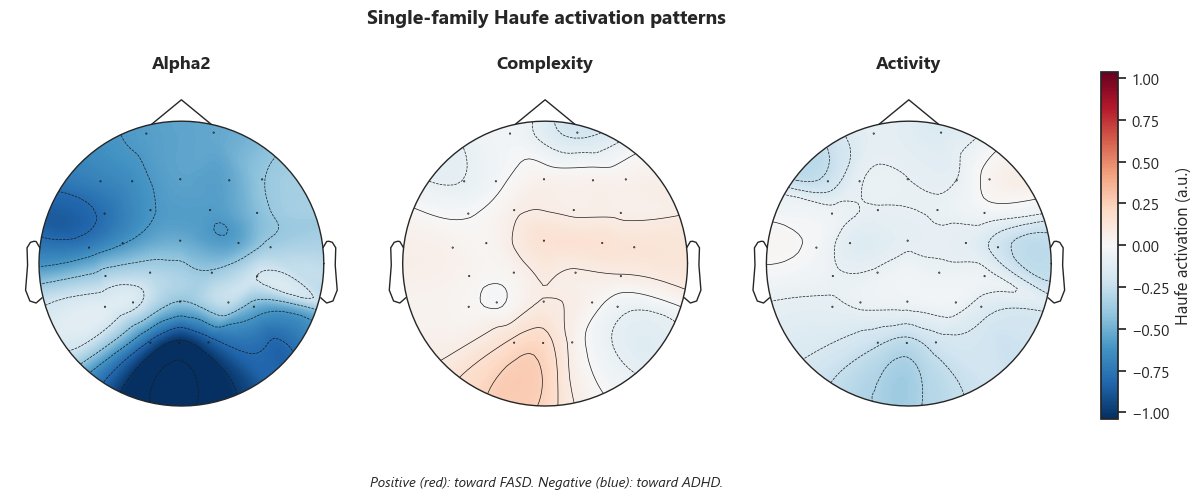

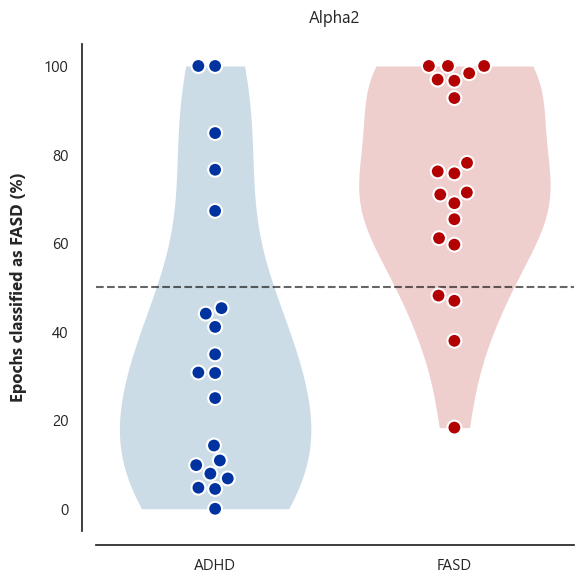

In [20]:
def voting_margins_table(voting_path, families):
    """Mean percentage of epochs voted FASD per diagnosis, voting margin and subject-level correct classifications."""
    warnings.filterwarnings("ignore", category=UserWarning)
    votes = pd.read_excel(voting_path)
    rows = []
    for family in families:
        sub = votes[votes["Evaluated_Feature"] == family]
        fasd = sub[sub["Real_Label"] == 1]["FASD_Vote_Pct"]
        adhd = sub[sub["Real_Label"] == 0]["FASD_Vote_Pct"]
        rows.append({
            "Feature": family,
            "FASD mean (%)": round(fasd.mean(), 1),
            "ADHD mean (%)": round(adhd.mean(), 1),
            "Voting margin (pp)": round(fasd.mean() - adhd.mean(), 1), 
            "FASD correct": f"{(fasd >= 50).sum()}/{len(fasd)}",
            "ADHD correct": f"{(adhd < 50).sum()}/{len(adhd)}",
        })
    return pd.DataFrame(rows)


def plot_haufe_topomaps(haufe_path, families, save_path=None):
    """Average Haufe activation patterns across outer folds, one topomap per feature family with a shared colour scale."""
    df_haufe = pd.read_excel(haufe_path)
    info = mne.create_info(ch_names=df_haufe["Channel"].tolist(), sfreq=500, ch_types="eeg")
    info.set_montage("standard_1020")

    values = {f: df_haufe[f].values for f in families}
    limit = max(max(np.max(np.abs(v)) for v in values.values()), 1e-5)

    fig = plt.figure(figsize=(4.5 * len(families) + 0.8, 4.5))
    grid = gridspec.GridSpec(1, len(families) + 1, width_ratios=[1] * len(families) + [0.05], wspace=0.08)
    axes = [fig.add_subplot(grid[0, i]) for i in range(len(families))]
    colorbar_ax = fig.add_subplot(grid[0, len(families)])

    for ax, family in zip(axes, families):
        image, _ = mne.viz.plot_topomap(
            values[family], info, axes=ax, show=False, cmap="RdBu_r", vlim=(-limit, limit),
            extrapolate="head", sphere=(0, 0, 0, 0.11), contours=6,
        )
        ax.set_title(family, fontsize=13, fontweight="bold", pad=12)

    fig.colorbar(image, cax=colorbar_ax).set_label("Haufe activation (a.u.)", fontsize=12)
    fig.text(0.5, -0.04, "Positive (red): toward FASD. Negative (blue): toward ADHD.",
             ha="center", fontsize=10, fontstyle="italic")
    plt.suptitle("Single-family Haufe activation patterns", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    return fig


def plot_voting_distribution(voting_path, family, save_path=None):
    """Percentage of each subject's epochs classified as FASD, by true diagnosis."""
    votes = pd.read_excel(voting_path)
    sub = votes[votes["Evaluated_Feature"] == family].copy()
    sub["Diagnosis"] = sub["Real_Label"].map({0: "ADHD", 1: "FASD"})
    sub["Status"] = np.where(
        ((sub["Diagnosis"] == "ADHD") & (sub["FASD_Vote_Pct"] < 50)) | ((sub["Diagnosis"] == "FASD") & (sub["FASD_Vote_Pct"] >= 50)),
        sub["Diagnosis"] + "_correct", sub["Diagnosis"] + "_misclassified",
    )
    point_colors = {"ADHD_correct": "#0033a0", "ADHD_misclassified": "#0033a0",
                    "FASD_correct": "#b30000", "FASD_misclassified": "#b30000"}

    fig, ax = plt.subplots(figsize=(6, 6))
    sns.violinplot(data=sub, x="Diagnosis", y="FASD_Vote_Pct", hue="Diagnosis", palette={"ADHD": "#1f77b4", "FASD": "#d62728"},
                   inner=None, linewidth=0, alpha=0.25, cut=0, legend=False, ax=ax)
    sns.swarmplot(data=sub, x="Diagnosis", y="FASD_Vote_Pct", hue="Status", palette=point_colors,
                  edgecolor="white", linewidth=1.5, size=10, zorder=2, ax=ax)
    ax.axhline(50, color="black", linestyle="--", linewidth=1.5, alpha=0.6, zorder=1)
    ax.set_title(family, pad=15)
    ax.set_xlabel("")
    ax.set_ylabel("Epochs classified as FASD (%)", fontweight="bold", labelpad=12)
    ax.set_ylim(-5, 105)
    if ax.legend_ is not None:
        ax.legend_.remove()
    sns.despine(trim=False, offset=10)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    return fig


margins_single = voting_margins_table(PATH_SINGLE_FAMILY / SINGLE_FAMILY_FILES["voting"], qualifying_single)
margins_single.to_excel(PATH_SINGLE_FAMILY / "Voting_margins.xlsx", index=False)
report_style(margins_single, "Subject-level voting margins of the qualifying single-family models")

_ = plot_haufe_topomaps(PATH_SINGLE_FAMILY / SINGLE_FAMILY_FILES["haufe"], qualifying_single,
                        PATH_SINGLE_FAMILY / "Haufe_single_family.png")
_ = plot_voting_distribution(PATH_SINGLE_FAMILY / SINGLE_FAMILY_FILES["voting"], qualifying_single[0],
                             PATH_SINGLE_FAMILY / f"Voting_{qualifying_single[0]}.png")

## 9. Paired-family EEG models

In [25]:
RUN_PAIRED_FAMILY = False  # True refits the 91 paired-family models (several hours in total)
SCREENING_AUC_PAIRED = 0.70

PAIRED_FAMILY_FILES = {
    "subject": "A1_NESTED_paired_family_eeg_SUBJECT.xlsx",
    "epoch": "A1_NESTED_paired_family_eeg_SEGMENT.xlsx",
    "c_log": "E1_C_SELECTION_LOG_paired_family_eeg.xlsx",
}
PAIR_LABELS = {"Complexity + Alpha2": "Alpha2 + Complexity"}  # model name -> name used in the tables


def pair_label(model):
    return PAIR_LABELS.get(model, model)


def pair_file_key(model):
    return model.replace(" + ", "_")


def run_paired_family_models(df_eeg, df_demo, families, output_dir, c_grid=C_GRID):
    """Fit one nested-LOSO L1-SVM per pair of feature families (all channels of both) and save summaries, spatial tables and predictions."""
    output_dir = Path(output_dir)
    roc_dir = output_dir / "ROC_SUBJECT"
    roc_dir.mkdir(parents=True, exist_ok=True)

    subject_rows, epoch_rows, c_log = [], [], []

    for family_a, family_b in combinations(families, 2):
        model = f"{family_a} + {family_b}"
        columns = family_feature_columns(df_eeg, [family_a, family_b])
        if not columns:
            continue

        report_df, df_stab, _, df_pat, selected_cs = execute_nested_loso_pipeline(
            df_eeg, columns, df_demo, c_grid=c_grid, model_title=model
        )
        subject_rows.append({**report_df.iloc[0].to_dict(), "Model": model})
        epoch_rows.append({**report_df.iloc[1].to_dict(), "Model": model})
        c_log.append({"Model": model, "C_values_selected": selected_cs,
                      "C_mode": max(set(selected_cs), key=selected_cs.count)})

        df_stab.to_excel(output_dir / f"C1_paired_family_eeg_NESTED_SPATIAL_{pair_file_key(model)}.xlsx", index=False)
        df_pat.to_excel(roc_dir / f"ROC_SUBJECT_{pair_file_key(model)}.xlsx", index=False)
        gc.collect()

    df_sub = pd.DataFrame(subject_rows).sort_values("_raw_auc", ascending=False)
    df_seg = pd.DataFrame(epoch_rows).sort_values("_raw_auc", ascending=False)
    df_sub.to_excel(output_dir / PAIRED_FAMILY_FILES["subject"], index=False)
    df_seg.to_excel(output_dir / PAIRED_FAMILY_FILES["epoch"], index=False)
    pd.DataFrame(c_log).to_excel(output_dir / PAIRED_FAMILY_FILES["c_log"], index=False)
    return df_sub, df_seg


if RUN_PAIRED_FAMILY:
    df_sub_paired, df_seg_paired = run_paired_family_models(
        df_master_eeg, df_demo_balanced, EEG_FEATURE_FAMILIES, PATH_PAIRED_FAMILY
    )
else:
    df_sub_paired = load_model_summary(PATH_PAIRED_FAMILY / PAIRED_FAMILY_FILES["subject"])
    df_seg_paired = load_model_summary(PATH_PAIRED_FAMILY / PAIRED_FAMILY_FILES["epoch"])

paired_table = performance_table(df_seg_paired, df_sub_paired, "Model", SCREENING_AUC_PAIRED, extended=True, inclusive=True)
paired_table["Model"] = paired_table["Model"].map(pair_label)
n_qualifying_paired = int((df_seg_paired["_raw_auc"] >= SCREENING_AUC_PAIRED).sum())
passed = df_sub_paired[df_sub_paired["Model"].isin(df_seg_paired.loc[df_seg_paired["_raw_auc"] >= SCREENING_AUC_PAIRED, "Model"])]
qualifying_paired = passed.sort_values("_raw_auc", ascending=False)["Model"].tolist()  # model names, by subject-level AUC

report_style(
    paired_table.head(n_qualifying_paired)[["Model", "Epoch AUC", "Epoch accuracy", "Subject AUC (SE)",
                                            "Subject accuracy (SE)", "Sensitivity (SE)", "Specificity (SE)"]],
    f"Paired-family EEG models qualifying for multimodal integration (epoch AUC >= {SCREENING_AUC_PAIRED:.2f})",
)
report_style(paired_table, f"All {len(paired_table)} paired-family EEG models")

Model,Epoch AUC,Epoch accuracy,Subject AUC (SE),Subject accuracy (SE),Sensitivity (SE),Specificity (SE)
Alpha2 + Complexity,0.727,0.675,0.820 (0.071),0.775 (0.066),0.750 (0.102),0.800 (0.087)
Alpha2 + Beta1,0.719,0.680,0.783 (0.078),0.825 (0.061),0.850 (0.083),0.800 (0.091)
Alpha2 + Beta,0.702,0.686,0.745 (0.082),0.775 (0.068),0.850 (0.083),0.700 (0.106)


Model,Epoch AUC,Epoch accuracy,Subject AUC (SE),Subject accuracy (SE),Sensitivity (SE),Specificity (SE),Precision (SE),Net benefit (SE)
Alpha2 + Complexity,0.727,0.675,0.820 (0.071),0.775 (0.066),0.750 (0.102),0.800 (0.087),0.789 (0.094),0.275 (0.101)
Alpha2 + Beta1,0.719,0.680,0.783 (0.078),0.825 (0.061),0.850 (0.083),0.800 (0.091),0.810 (0.089),0.225 (0.103)
Alpha2 + Beta,0.702,0.686,0.745 (0.082),0.775 (0.068),0.850 (0.083),0.700 (0.106),0.739 (0.095),0.200 (0.109)
Alpha2 + TBR,0.692,0.663,0.768 (0.078),0.775 (0.066),0.850 (0.081),0.700 (0.102),0.739 (0.094),0.225 (0.110)
Delta + Alpha2,0.689,0.660,0.748 (0.079),0.700 (0.073),0.700 (0.105),0.700 (0.100),0.700 (0.104),0.175 (0.107)
Alpha2 + HFD,0.686,0.645,0.715 (0.083),0.675 (0.074),0.650 (0.106),0.700 (0.105),0.684 (0.112),0.175 (0.107)
Theta + Alpha2,0.685,0.652,0.755 (0.079),0.750 (0.068),0.800 (0.090),0.700 (0.102),0.727 (0.098),0.175 (0.114)
Mobility + Alpha2,0.682,0.656,0.740 (0.083),0.725 (0.072),0.800 (0.092),0.650 (0.107),0.696 (0.099),0.275 (0.109)
Alpha2 + Beta2,0.679,0.667,0.730 (0.082),0.700 (0.073),0.750 (0.099),0.650 (0.110),0.682 (0.103),0.250 (0.106)
Alpha2 + SampEn,0.679,0.645,0.750 (0.081),0.775 (0.067),0.800 (0.092),0.750 (0.099),0.762 (0.096),0.250 (0.109)


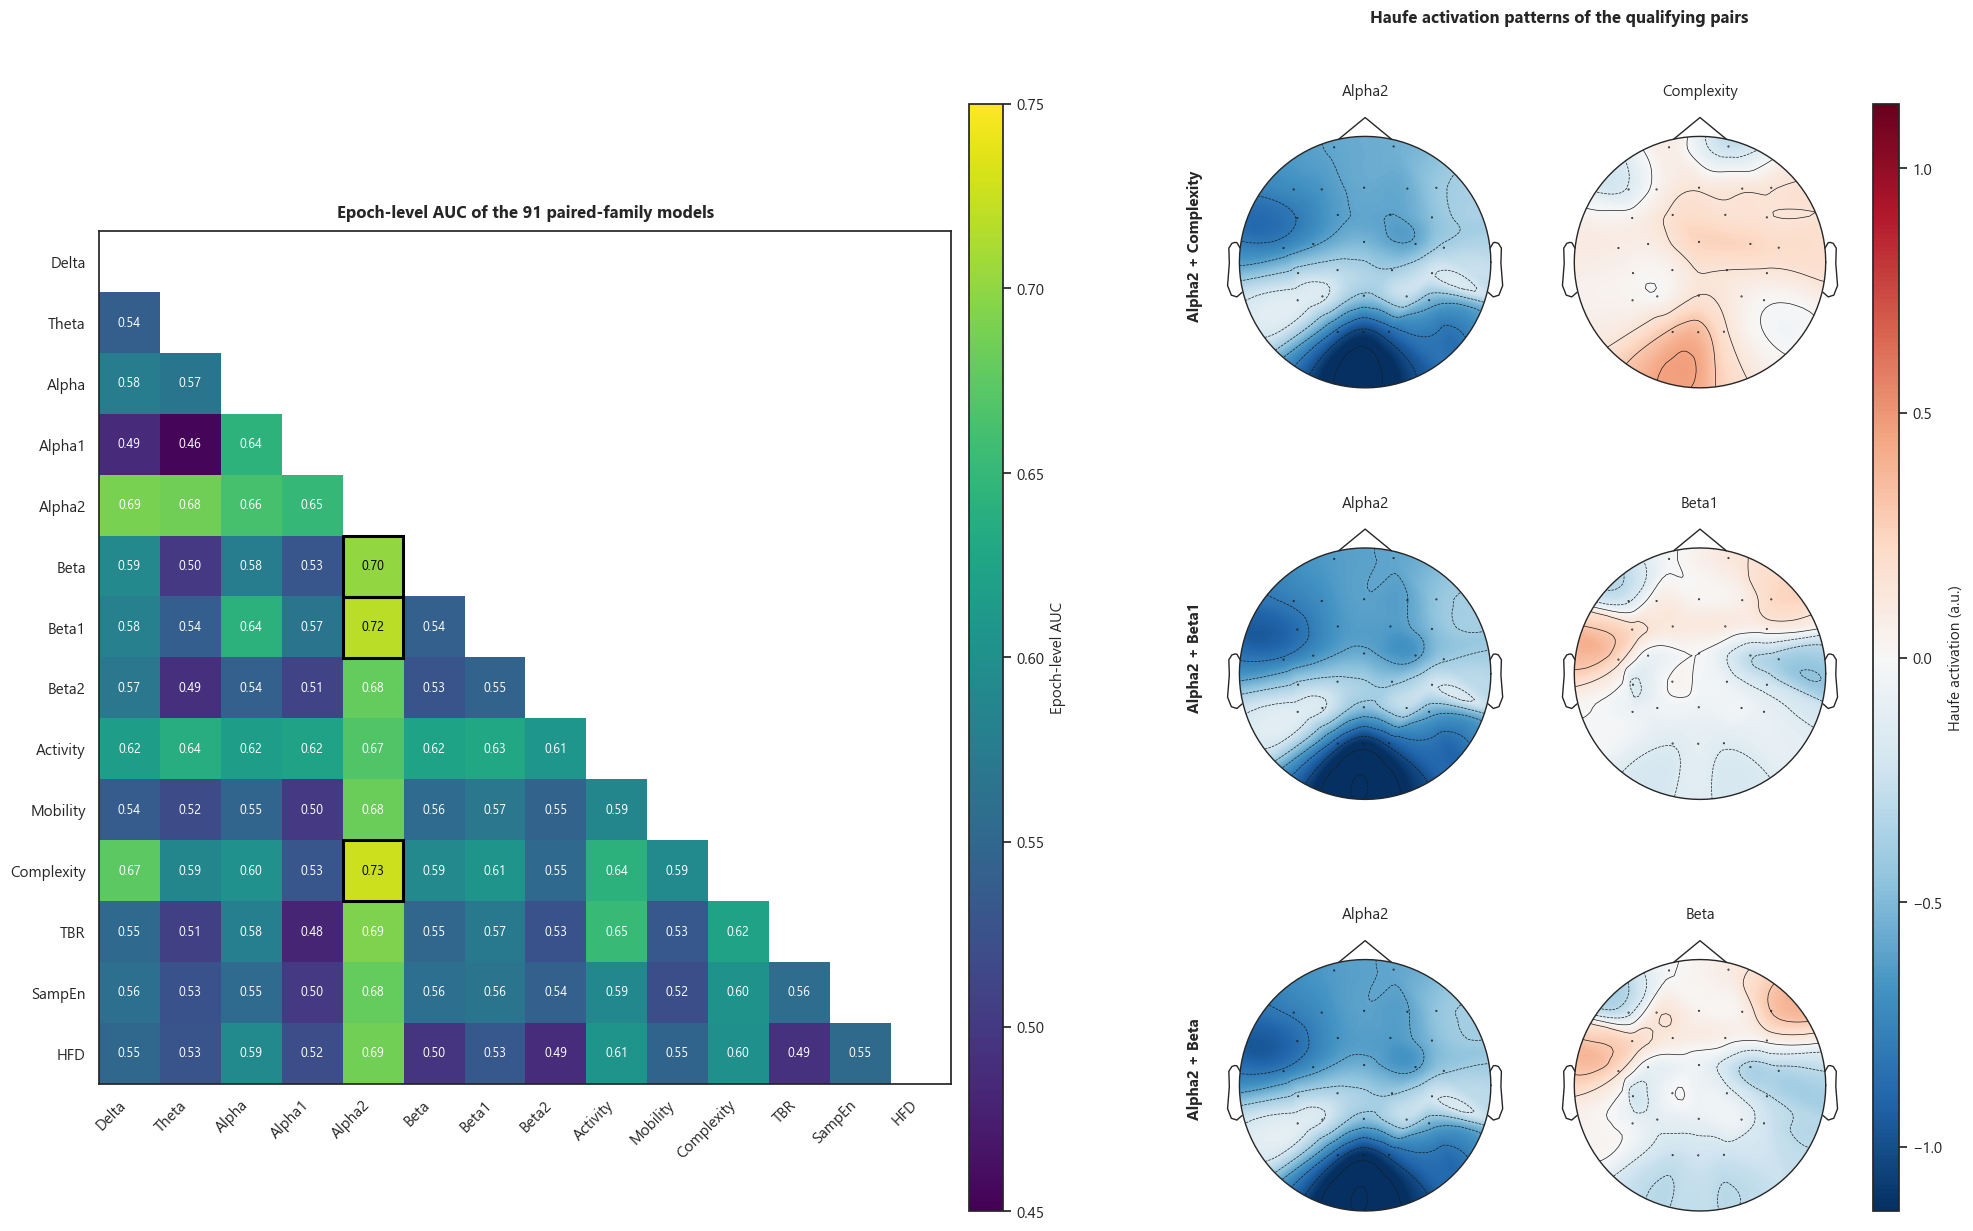

In [26]:
def load_paired_haufe(spatial_dir, model):
    """Haufe activation per channel for each of the two feature families of a paired-family model."""
    table = pd.read_excel(spatial_dir / f"C1_paired_family_eeg_NESTED_SPATIAL_{pair_file_key(model)}.xlsx")
    table[["Channel", "Family"]] = table["Feature_Name"].str.rsplit("_", n=1, expand=True)
    return {family: group.reset_index(drop=True) for family, group in table.groupby("Family")}


def plot_paired_family_panel(df_seg, spatial_dir, qualifying_models, save_path=None):
    """Left: epoch-level AUC of all paired-family models (qualifying pairs outlined). Right: Haufe topomaps of the qualifying pairs."""
    display_order = ["Delta", "Theta", "Alpha", "Alpha1", "Alpha2", "Beta", "Beta1", "Beta2",
                     "Activity", "Mobility", "Complexity", "TBR", "SampEn", "HFD"]
    index = {f: i for i, f in enumerate(display_order)}
    auc = np.full((len(display_order), len(display_order)), np.nan)
    for _, row in df_seg.iterrows():
        a, b = row["Model"].split(" + ")
        auc[index[a], index[b]] = auc[index[b], index[a]] = row["_raw_auc"]
    n = len(display_order)
    lower_only = np.ma.array(auc, mask=np.triu(np.ones((n, n), dtype=bool)))

    haufe = {m: load_paired_haufe(spatial_dir, m) for m in qualifying_models}
    limit = max(max(np.abs(g["Haufe_Contribution"]).max() for g in h.values()) for h in haufe.values()) or 1e-5

    fig = plt.figure(figsize=(20, 4.5 * len(qualifying_models)))
    outer = gridspec.GridSpec(1, 2, width_ratios=[1.3, 1], wspace=0.25)
    left = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[0], width_ratios=[1, 0.04], wspace=0.04)
    ax_heat, ax_heat_bar = fig.add_subplot(left[0, 0]), fig.add_subplot(left[0, 1])
    right = gridspec.GridSpecFromSubplotSpec(len(qualifying_models), 3, subplot_spec=outer[1],
                                             width_ratios=[1, 1, 0.08], hspace=0.45, wspace=0.05)

    cmap = plt.cm.viridis.copy()
    cmap.set_bad(color="white")
    image = ax_heat.imshow(lower_only, cmap=cmap, vmin=0.45, vmax=0.75, aspect="equal")
    ax_heat.set_xticks(range(n)); ax_heat.set_yticks(range(n))
    ax_heat.set_xticklabels(display_order, rotation=45, ha="right", fontsize=11)
    ax_heat.set_yticklabels(display_order, fontsize=11)
    ax_heat.set_title(f"Epoch-level AUC of the {len(df_seg)} paired-family models", fontsize=12, fontweight="bold", pad=10)
    for i in range(n):
        for j in range(i):
            if not np.isnan(auc[i, j]):
                ax_heat.text(j, i, f"{auc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                             color="black" if auc[i, j] > 0.70 else "white")
    for model in qualifying_models:
        a, b = model.split(" + ")
        ax_heat.add_patch(plt.Rectangle((min(index[a], index[b]) - 0.5, max(index[a], index[b]) - 0.5), 1, 1,
                                        fill=False, edgecolor="black", linewidth=2.2, zorder=5))
    fig.colorbar(image, cax=ax_heat_bar).set_label("Epoch-level AUC", fontsize=11)

    topo = None
    for row, model in enumerate(qualifying_models):
        families = pair_label(model).split(" + ")
        for col, family in enumerate(families):
            ax = fig.add_subplot(right[row, col])
            values = haufe[model][family]
            info = mne.create_info(ch_names=values["Channel"].tolist(), sfreq=500, ch_types="eeg")
            info.set_montage("standard_1020")
            topo, _ = mne.viz.plot_topomap(values["Haufe_Contribution"].values, info, axes=ax, show=False, cmap="RdBu_r",
                                           vlim=(-limit, limit), extrapolate="head", sphere=(0, 0, 0, 0.11), contours=6)
            ax.set_title(family, fontsize=11, pad=6)
            if col == 0:
                ax.set_ylabel(pair_label(model), fontsize=11, fontweight="bold", labelpad=8)
    fig.colorbar(topo, cax=fig.add_subplot(right[:, 2])).set_label("Haufe activation (a.u.)", fontsize=11)
    fig.suptitle("Haufe activation patterns of the qualifying pairs", fontsize=12, fontweight="bold", x=0.78, y=0.99)
    plt.subplots_adjust(left=0.05, right=0.95, top=0.92, bottom=0.1)
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    return fig


_ = plot_paired_family_panel(df_seg_paired, PATH_PAIRED_FAMILY, qualifying_paired,
                             PATH_PAIRED_FAMILY / "Paired_family_AUC_and_Haufe.png")

## 10. Multimodal models

In [27]:
RUN_MULTIMODAL = False  # True refits the 6 multimodal models
MULTIMODAL_EEG_SCENARIOS = [
    ["Complexity"], ["Alpha2"], ["Activity"],
    ["Alpha2", "Complexity"], ["Alpha2", "Beta1"], ["Alpha2", "Beta"],
]
MULTIMODAL_FILES = {
    "subject": "A1_NESTED_MULTIMODAL_SUBJECT.xlsx",
    "epoch": "A1_NESTED_MULTIMODAL_SEGMENT.xlsx",
    "c_log": "E1_C_SELECTION_LOG_MULTIMODAL.xlsx",
}


def multimodal_name(eeg_families, np_features):
    return f"EEG({' + '.join(eeg_families)}) + NP({' + '.join(np_features)})"


def multimodal_id(eeg_families):
    return "_".join(eeg_families) + "_with_NP"


def run_multimodal_models(df_eeg, df_np, df_demo, scenarios, np_features, output_dir, c_grid=C_GRID):
    """Fit one nested-LOSO L1-SVM per EEG scenario, each combined with the same NP scores (repeated across the epochs of a subject)."""
    output_dir = Path(output_dir)
    roc_dir = output_dir / "ROC_SUBJECT"
    roc_dir.mkdir(parents=True, exist_ok=True)

    df_np_subject = df_np[["Subject"] + np_features].drop_duplicates(subset=["Subject"])
    df_joint = pd.merge(df_eeg, df_np_subject, on="Subject", how="inner")

    subject_rows, epoch_rows, c_log = [], [], []
    for eeg_families in scenarios:
        model = multimodal_name(eeg_families, np_features)
        columns = family_feature_columns(df_joint, eeg_families) + np_features

        report_df, df_stab, _, df_pat, selected_cs = execute_nested_loso_pipeline(
            df_joint, columns, df_demo, c_grid=c_grid, model_title=model
        )
        subject_rows.append({**report_df.iloc[0].to_dict(), "Model": model})
        epoch_rows.append({**report_df.iloc[1].to_dict(), "Model": model})
        c_log.append({"Model": model, "C_values_selected": selected_cs,
                      "C_mode": max(set(selected_cs), key=selected_cs.count)})

        df_pat.to_excel(roc_dir / f"ROC_SUBJECT_{multimodal_id(eeg_families)}.xlsx", index=False)
        df_stab.to_excel(output_dir / f"C_MULTIMODAL_NESTED_STABILITY_{multimodal_id(eeg_families)}.xlsx", index=False)
        gc.collect()

    df_sub = pd.DataFrame(subject_rows).sort_values("_raw_auc", ascending=False)
    df_seg = pd.DataFrame(epoch_rows).sort_values("_raw_auc", ascending=False)
    df_sub.to_excel(output_dir / MULTIMODAL_FILES["subject"], index=False)
    df_seg.to_excel(output_dir / MULTIMODAL_FILES["epoch"], index=False)
    pd.DataFrame(c_log).to_excel(output_dir / MULTIMODAL_FILES["c_log"], index=False)
    return df_sub, df_seg


def multimodal_table(df_seg, df_sub, extended=True):
    """Performance table with the EEG and NP components of each model in separate columns, ordered by subject-level AUC."""
    table = performance_table(df_seg, df_sub, "Model", screening_auc=-1, extended=extended)
    parts = table["Model"].str.extract(r"EEG\((?P<EEG>.*)\) \+ NP\((?P<NP>.*)\)")
    parts["NP"] = parts["NP"].map(lambda s: " + ".join(NP_LABELS[f] for f in s.split(" + ")))
    return pd.concat([parts, table.drop(columns="Model")], axis=1).rename(columns={"NP": "NP scores"})


df_np_balanced = pd.read_excel(PATH_NP_SCORES_BALANCED)

if RUN_MULTIMODAL:
    df_sub_multimodal, df_seg_multimodal = run_multimodal_models(
        df_master_eeg, df_np_balanced, df_demo_balanced, MULTIMODAL_EEG_SCENARIOS, stable_np_features, PATH_MULTIMODAL
    )
else:
    df_sub_multimodal = load_model_summary(PATH_MULTIMODAL / MULTIMODAL_FILES["subject"])
    df_seg_multimodal = load_model_summary(PATH_MULTIMODAL / MULTIMODAL_FILES["epoch"])

multimodal_results = multimodal_table(df_seg_multimodal, df_sub_multimodal)
report_style(multimodal_results, "Multimodal models (EEG + FSIQ and Stroop-WC)")

EEG,NP scores,Epoch AUC,Epoch accuracy,Subject AUC (SE),Subject accuracy (SE),Sensitivity (SE),Specificity (SE),Precision (SE),Net benefit (SE)
Complexity,FSIQ + Stroop-WC,0.850,0.781,0.860 (0.064),0.800 (0.062),0.850 (0.083),0.750 (0.096),0.773 (0.089),0.300 (0.107)
Alpha2 + Complexity,FSIQ + Stroop-WC,0.846,0.788,0.860 (0.061),0.825 (0.059),0.900 (0.071),0.750 (0.094),0.783 (0.086),0.325 (0.108)
Alpha2,FSIQ + Stroop-WC,0.834,0.776,0.830 (0.066),0.775 (0.066),0.850 (0.085),0.700 (0.101),0.739 (0.091),0.275 (0.111)
Activity,FSIQ + Stroop-WC,0.823,0.761,0.825 (0.070),0.775 (0.065),0.850 (0.083),0.700 (0.101),0.739 (0.091),0.275 (0.111)
Alpha2 + Beta1,FSIQ + Stroop-WC,0.783,0.743,0.795 (0.073),0.750 (0.069),0.800 (0.093),0.700 (0.101),0.727 (0.095),0.250 (0.110)
Alpha2 + Beta,FSIQ + Stroop-WC,0.792,0.749,0.785 (0.075),0.775 (0.067),0.800 (0.093),0.750 (0.095),0.762 (0.095),0.275 (0.107)


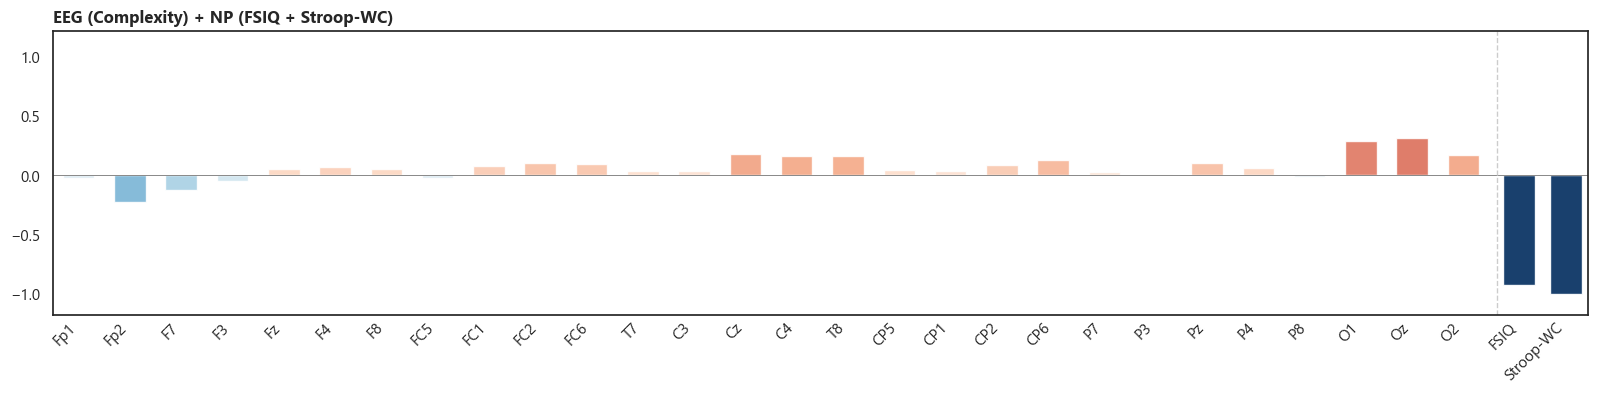

In [28]:
def load_multimodal_haufe(path, np_features, eeg_families):
    """Split a multimodal stability table into EEG (channel, family) and NP Haufe contributions."""
    table = pd.read_excel(path)
    table["Feature_Name"] = table["Feature_Name"].astype(str).str.strip()
    is_np = table["Feature_Name"].isin(np_features)

    haufe_eeg = {}
    for name, value in table.loc[~is_np, ["Feature_Name", "Haufe_Contribution"]].itertuples(index=False):
        family = next(f for f in sorted(eeg_families, key=len, reverse=True) if name.endswith(f"_{f}"))
        haufe_eeg[(name[: -len(family) - 1], family)] = value
    haufe_np = {NP_LABELS[name]: value for name, value in table.loc[is_np, ["Feature_Name", "Haufe_Contribution"]].itertuples(index=False)}

    peak = np.max(np.abs(list(haufe_eeg.values()) + list(haufe_np.values()))) or 1.0
    return haufe_eeg, haufe_np, peak


def draw_haufe_bars(ax, haufe_eeg, haufe_np, peak, eeg_families, colors, np_labels, title, diverging=False):
    """Bars of the normalised Haufe activation: one per channel and EEG family, followed by the NP scores."""
    n_eeg = len(eeg_families)
    bar_w = 0.40 if n_eeg == 1 else 0.36
    gap_intra, gap_inter, np_sep, np_gap = 0.02, (0.25 if n_eeg == 1 else 0.10), 0.5, 0.20

    group_w = n_eeg * bar_w + max(0, n_eeg - 1) * gap_intra
    x_channels = np.arange(len(EXPECTED_EEG_CHANNELS)) * (group_w + gap_inter)
    offsets = [0.0] if n_eeg == 1 else [-(bar_w / 2 + gap_intra / 2), bar_w / 2 + gap_intra / 2]
    x_np_start = x_channels[-1] + group_w / 2 + np_sep
    x_np = np.array([x_np_start + i * (bar_w + np_gap) for i in range(len(np_labels))])
    cmap = plt.get_cmap("RdBu_r")

    def color_of(height, default):
        if not diverging:
            return default
        ratio = np.clip(height / peak, -1.0, 1.0)
        return cmap(0.5 + 0.5 * np.sign(ratio) * np.abs(ratio) ** 0.55)

    for family, color, offset in zip(eeg_families, colors, offsets):
        heights = np.array([haufe_eeg.get((ch, family), 0.0) / peak for ch in EXPECTED_EEG_CHANNELS])
        ax.bar(x_channels + offset, heights, width=bar_w, alpha=0.88,
               color=[color_of(h, color) for h in heights])
    for x, label in zip(x_np, np_labels):
        height = haufe_np.get(label, 0.0) / peak
        ax.bar(x, height, width=bar_w, alpha=0.92, color=color_of(height, "#E59866"))

    x_separator = x_channels[-1] + group_w / 2 + np_sep * 0.45
    ax.axhline(0, color="#888888", lw=0.7)
    ax.axvline(x_separator, color="#cccccc", lw=1.0, ls="--")
    ax.set_xticks(list(x_channels) + list(x_np))
    ax.set_xticklabels(EXPECTED_EEG_CHANNELS + np_labels, rotation=45, ha="right", fontsize=11)
    ax.set_ylim([-1.18, 1.22])
    ax.set_yticks([-1.0, -0.5, 0, 0.5, 1.0])
    ax.tick_params(axis="x", length=0)
    ax.set_title(title, fontsize=12, fontweight="bold", loc="left")

    if diverging:
        ax.set_xlim(x_channels[0] - group_w * 0.8, x_np[-1] + (x_np[0] - x_separator))
    else:
        ax.set_xlim(x_channels[0] - group_w * 0.8, x_np[-1] + bar_w * 1.8)
        ax.text(x_np.mean(), 1.10, "NP", fontsize=9, color="#7D4B00", ha="center", fontweight="bold")
        handles = [mpatches.Patch(color=c, alpha=0.88, label=f"EEG ({f})") for f, c in zip(eeg_families, colors)]
        handles.append(mpatches.Patch(color="#E59866", alpha=0.92, label="NP (FSIQ + Stroop-WC)"))
        ax.legend(handles=handles, loc="upper right", fontsize=9, frameon=True)


LEADING_MULTIMODAL = [
    {"eeg": ["Complexity"], "colors": ["#2E86C1"]},
    {"eeg": ["Alpha2", "Complexity"], "colors": ["#1A5276", "#2E86C1"]},
    {"eeg": ["Alpha2"], "colors": ["#1A5276"]},
]
np_labels = [NP_LABELS[f] for f in stable_np_features]


def stability_path(eeg_families):
    return PATH_MULTIMODAL / f"C_MULTIMODAL_NESTED_STABILITY_{multimodal_id(eeg_families)}.xlsx"


# Optimal multimodal model, diverging colour scale
fig, ax = plt.subplots(figsize=(16.5, 4.3))
plt.subplots_adjust(left=0.05, right=0.98, top=0.88, bottom=0.22)
best = LEADING_MULTIMODAL[0]
haufe_eeg, haufe_np, peak = load_multimodal_haufe(stability_path(best["eeg"]), stable_np_features, best["eeg"])
draw_haufe_bars(ax, haufe_eeg, haufe_np, peak, best["eeg"], best["colors"], np_labels,
                f"EEG ({best['eeg'][0]}) + NP (FSIQ + Stroop-WC)", diverging=True)
fig.savefig(PATH_MULTIMODAL / "Haufe_multimodal_optimal_model.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 11. Performance tables and model comparison

In [29]:
RUN_COMPARISONS = False  # True repeats the paired bootstrap tests (about 10 minutes)
N_BOOT_COMPARISON = 5000
ALPHA = 0.05

NP_MODEL = " + ".join(NP_LABELS[f] for f in stable_np_features)  # "FSIQ + Stroop-WC"
SINGLE_MODELS = ["Alpha2", "Complexity", "Activity"]
PAIRED_MODELS = {"Alpha2 + Complexity": "Complexity_Alpha2", "Alpha2 + Beta1": "Alpha2_Beta1", "Alpha2 + Beta": "Alpha2_Beta"}
MULTIMODAL_MODELS = {
    f"{eeg} + {NP_MODEL}": multimodal_id(eeg.split(" + "))
    for eeg in ["Complexity", "Alpha2", "Alpha2 + Complexity", "Activity", "Alpha2 + Beta", "Alpha2 + Beta1"]
}
BEST_SINGLE, BEST_PAIRED = "Alpha2", "Alpha2 + Complexity"

PREDICTION_FILES = {
    NP_MODEL: PATH_NP_FEATURES / "ROC_SUBJECT_NP_baseline.xlsx",
    **{m: PATH_SINGLE_FAMILY / "ROC_SUBJECT" / f"ROC_SUBJECT_{m}.xlsx" for m in SINGLE_MODELS},
    **{m: PATH_PAIRED_FAMILY / "ROC_SUBJECT" / f"ROC_SUBJECT_{k}.xlsx" for m, k in PAIRED_MODELS.items()},
    **{m: PATH_MULTIMODAL / "ROC_SUBJECT" / f"ROC_SUBJECT_{k}.xlsx" for m, k in MULTIMODAL_MODELS.items()},
}


def comparison_plan():
    plan = [("Within single-family", a, b) for a, b in combinations(SINGLE_MODELS, 2)]
    plan += [("Within paired-family", a, b) for a, b in combinations(PAIRED_MODELS, 2)]
    plan += [("Paired-family vs best single-family", m, BEST_SINGLE) for m in PAIRED_MODELS]
    plan += [("Within multimodal", a, b) for a, b in combinations(MULTIMODAL_MODELS, 2)]
    for model in MULTIMODAL_MODELS:
        plan += [("Multimodal vs best single-family", model, BEST_SINGLE),
                 ("Multimodal vs best paired-family", model, BEST_PAIRED),
                 ("Multimodal vs NP baseline", model, NP_MODEL)]
    return plan


def load_predictions(path):
    table = pd.read_excel(path).sort_values("Subject").reset_index(drop=True)
    return table["Subject"].values, table["Real"].values, table["Prob"].values


def paired_bootstrap_auc(y_true, prob_a, prob_b, n_boot=N_BOOT_COMPARISON, seed=RANDOM_SEED):
    """Two-sided paired bootstrap p-value for the AUC difference between two models evaluated on the same subjects."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    auc_a, auc_b = roc_auc_score(y_true, prob_a), roc_auc_score(y_true, prob_b)
    observed = auc_a - auc_b

    differences = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        differences.append(roc_auc_score(y_true[idx], prob_a[idx]) - roc_auc_score(y_true[idx], prob_b[idx]))

    differences = np.array(differences)
    one_sided = np.mean(differences <= 0) if observed >= 0 else np.mean(differences >= 0)
    return auc_a, auc_b, observed, float(np.clip(2 * one_sided, 0, 1))


def run_pairwise_comparisons(prediction_files, plan):
    predictions = {name: load_predictions(path) for name, path in prediction_files.items()}
    subjects, y_true, _ = predictions[BEST_SINGLE]
    if any(not np.array_equal(s, subjects) or not np.array_equal(y, y_true) for s, y, _ in predictions.values()):
        raise ValueError("Models were evaluated on different subjects or labels.")

    rows = []
    for group, model_a, model_b in plan:
        auc_a, auc_b, delta, p = paired_bootstrap_auc(y_true, predictions[model_a][2], predictions[model_b][2])
        rows.append({
            "Comparison group": group, "Model A": model_a, "Model B": model_b,
            "AUC (A)": round(auc_a, 3), "AUC (B)": round(auc_b, 3),
            "Delta AUC (A - B)": round(delta, 3), "p-value": round(p, 3), "Significant": "*" if p < ALPHA else "",
        })
    return pd.DataFrame(rows)


COMPARISONS_PATH = PATH_COMPARISONS / f"AUC_Pairwise_Bootstrap_Comparisons_{N_BOOT_COMPARISON}.xlsx"

if RUN_COMPARISONS:
    df_comparisons = run_pairwise_comparisons(PREDICTION_FILES, comparison_plan())
    df_comparisons.to_excel(COMPARISONS_PATH, index=False)
else:
    df_comparisons = pd.read_excel(COMPARISONS_PATH, keep_default_na=False)

report_style(
    df_comparisons.assign(**{"p-value": df_comparisons["p-value"].map(fmt_p)}),
    f"Pairwise AUC comparisons: paired bootstrap (B = {N_BOOT_COMPARISON:,}, seed = {RANDOM_SEED})",
)

Comparison group,Model A,Model B,AUC (A),AUC (B),Delta AUC (A - B),p-value,Significant
Within single-family,Alpha2,Complexity,0.805,0.710,0.095,0.426,
Within single-family,Alpha2,Activity,0.805,0.630,0.175,0.092,
Within single-family,Complexity,Activity,0.710,0.630,0.080,0.496,
Within paired-family,Alpha2 + Complexity,Alpha2 + Beta1,0.820,0.783,0.037,0.562,
Within paired-family,Alpha2 + Complexity,Alpha2 + Beta,0.820,0.745,0.075,0.230,
Within paired-family,Alpha2 + Beta1,Alpha2 + Beta,0.783,0.745,0.038,0.262,
Paired-family vs best single-family,Alpha2 + Complexity,Alpha2,0.820,0.805,0.015,0.752,
Paired-family vs best single-family,Alpha2 + Beta1,Alpha2,0.783,0.805,-0.022,0.772,
Paired-family vs best single-family,Alpha2 + Beta,Alpha2,0.745,0.805,-0.060,0.382,
Within multimodal,Complexity + FSIQ + Stroop-WC,Alpha2 + FSIQ + Stroop-WC,0.860,0.830,0.030,0.276,


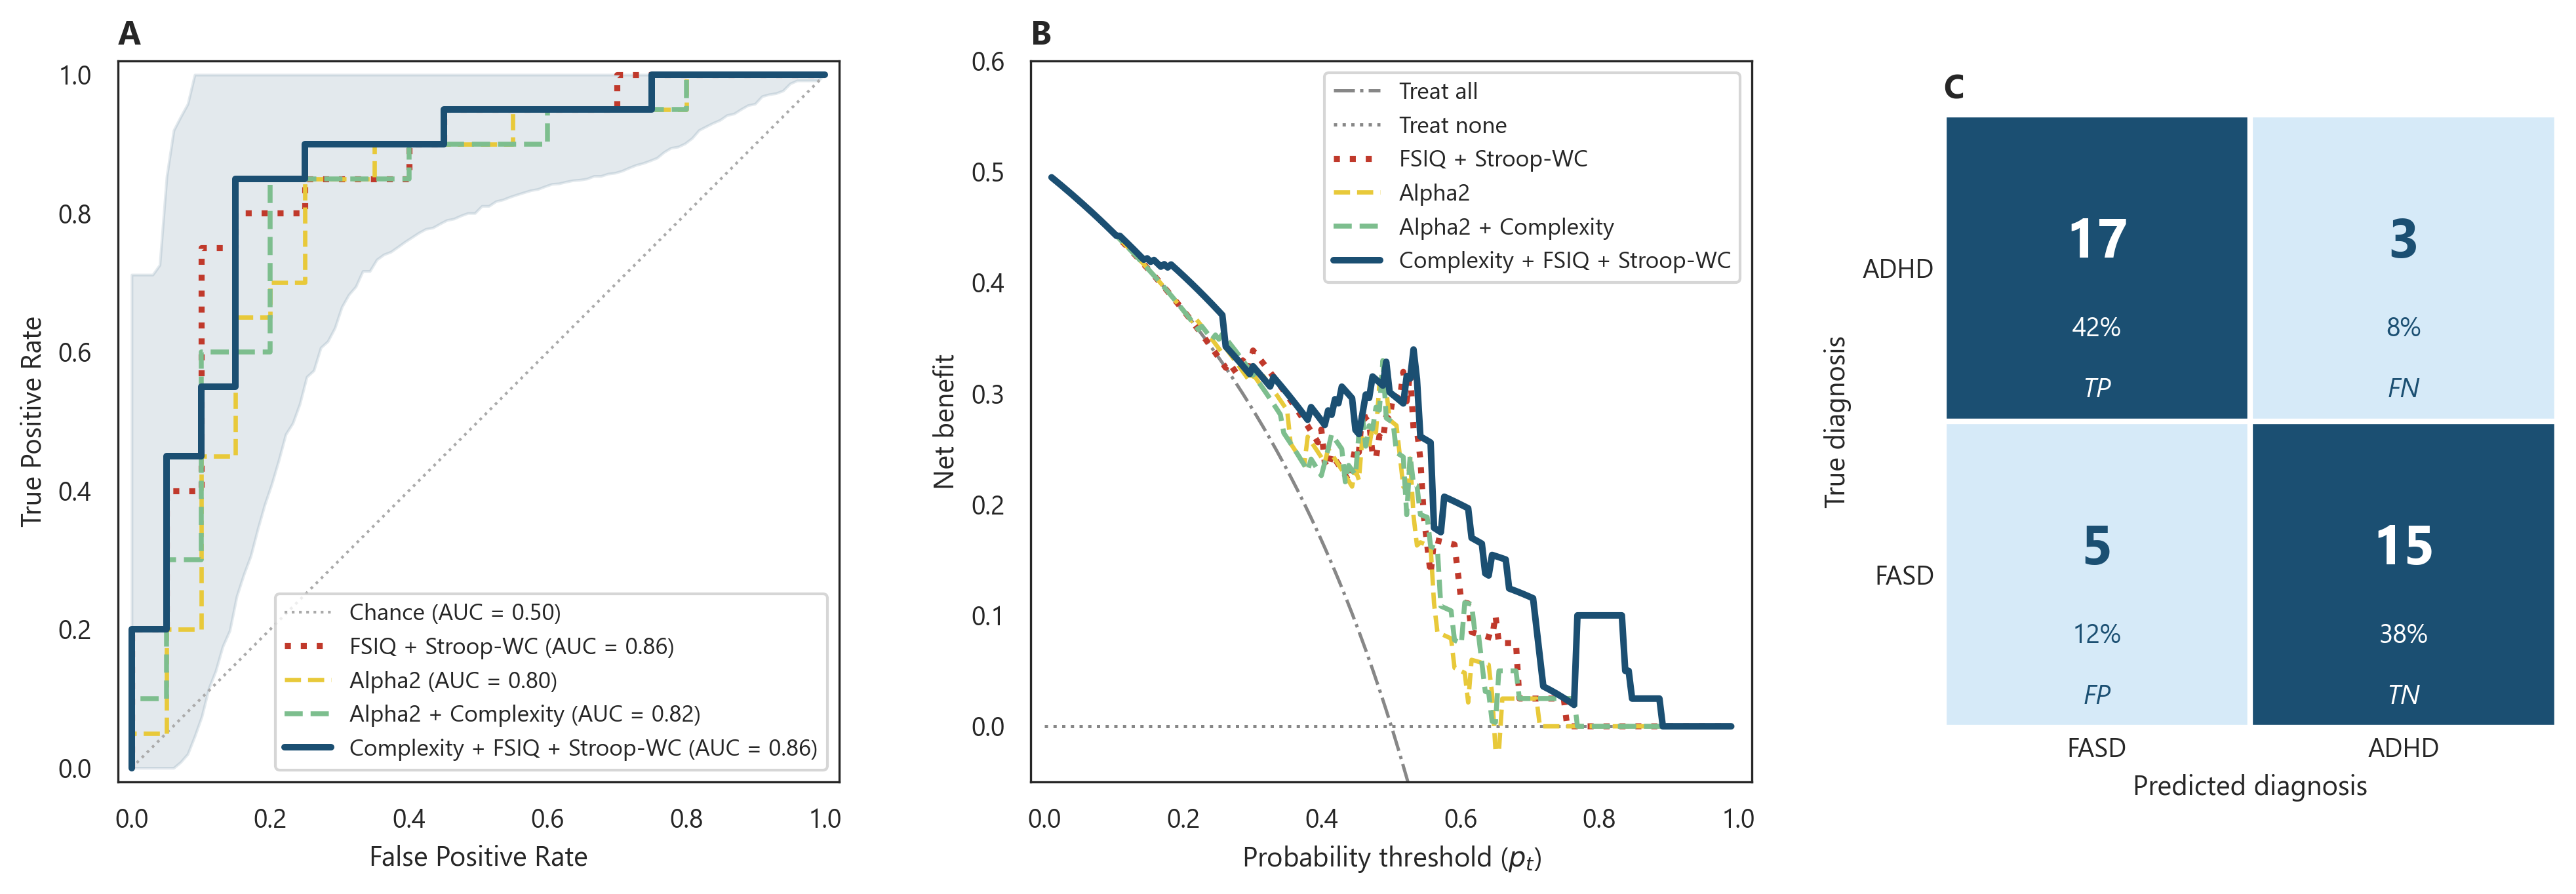

In [30]:
def bootstrap_roc_band(y_true, y_prob, n_boot=1000, seed=RANDOM_SEED):
    """Mean and standard deviation of the ROC curve across bootstrap resamples of the subjects."""
    rng = np.random.default_rng(seed)
    grid = np.linspace(0, 1, 100)
    curves = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        fpr, tpr, _ = roc_curve(y_true[idx], y_prob[idx])
        curves.append(np.interp(grid, fpr, tpr))
    curves = np.array(curves)
    return grid, curves.mean(axis=0), curves.std(axis=0)


def plot_performance_figure(models, best_label, save_path=None, confusion_matrix_panel=True):
    """ROC curves, decision curves and (optionally) the confusion matrix of the best model at pt = 0.50."""
    thresholds = np.linspace(0.01, 0.99, 200)
    predictions = {m["label"]: load_predictions(m["path"])[1:] for m in models}
    style = {"font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
             "axes.titlesize": 12, "legend.fontsize": 8.5, "axes.linewidth": 0.8}

    with plt.rc_context(style):
        n_panels = 3 if confusion_matrix_panel else 2
        fig = plt.figure(figsize=(16 if confusion_matrix_panel else 11, 5), dpi=300)
        grid = gridspec.GridSpec(1, n_panels, width_ratios=[1, 1, 0.85][:n_panels], wspace=0.28)
        ax_roc, ax_dca = fig.add_subplot(grid[0]), fig.add_subplot(grid[1])

        # ROC curves
        ax_roc.set_box_aspect(1)
        ax_roc.set_title("A", fontweight="bold", loc="left")
        handles, labels = [ax_roc.plot([0, 1], [0, 1], color="#AAAAAA", lw=1.0, ls=":")[0]], ["Chance (AUC = 0.50)"]
        for m in models:
            y_true, y_prob = predictions[m["label"]]
            fpr, tpr, _ = roc_curve(y_true, y_prob)
            handles.append(ax_roc.plot(fpr, tpr, color=m["color"], lw=m["lw"], ls=m["ls"])[0])
            labels.append(f"{m['label']} (AUC = {sk_auc(fpr, tpr):.2f})")
            if m.get("ci"):
                grid_fpr, mean_tpr, std_tpr = bootstrap_roc_band(y_true, y_prob)
                ax_roc.fill_between(grid_fpr, np.clip(mean_tpr - 1.96 * std_tpr, 0, 1),
                                    np.clip(mean_tpr + 1.96 * std_tpr, 0, 1), color=m["color"], alpha=0.12)
        ax_roc.set_xlim([-0.02, 1.02]); ax_roc.set_ylim([-0.02, 1.02])
        ax_roc.set_xlabel("False Positive Rate"); ax_roc.set_ylabel("True Positive Rate")
        ax_roc.legend(handles, labels, loc="lower right", frameon=True)

        # Decision curves
        ax_dca.set_box_aspect(1)
        ax_dca.set_title("B", fontweight="bold", loc="left")
        y_reference = predictions[models[0]["label"]][0]
        prevalence = np.mean(y_reference == 1)
        handles = [ax_dca.plot(thresholds, prevalence - (1 - prevalence) * thresholds / (1 - thresholds),
                               color="#555555", lw=1.2, ls="-.", alpha=0.7)[0],
                   ax_dca.plot([0, 1], [0, 0], color="#555555", lw=1.2, ls=":", alpha=0.7)[0]]
        labels = ["Treat all", "Treat none"]
        for m in models:
            y_true, y_prob = predictions[m["label"]]
            benefit = np.array([compute_net_benefit(y_true, y_prob, t) for t in thresholds])
            handles.append(ax_dca.plot(thresholds, np.clip(benefit, -0.05, None), color=m["color"], ls=m["ls"], lw=m["lw"])[0])
            labels.append(m["label"])
        ax_dca.set_xlim([-0.02, 1.02]); ax_dca.set_ylim([-0.05, 0.60])
        ax_dca.set_xlabel("Probability threshold ($p_t$)"); ax_dca.set_ylabel("Net benefit")
        ax_dca.legend(handles, labels, loc="upper right", frameon=True)

        # Confusion matrix
        if confusion_matrix_panel:
            ax_cm = fig.add_subplot(grid[2])
            ax_cm.set_box_aspect(1)
            ax_cm.set_title("C", fontweight="bold", loc="left")
            y_true, y_prob = predictions[best_label]
            counts = confusion_matrix(y_true, (y_prob >= 0.50).astype(int), labels=[1, 0])  # rows: true FASD, ADHD
            names = {(0, 0): "TP", (0, 1): "FN", (1, 0): "FP", (1, 1): "TN"}
            for i in range(2):
                for j in range(2):
                    dark = i == j
                    text_color = "white" if dark else "#1B4F72"
                    ax_cm.add_patch(plt.Rectangle((j, 1 - i), 1, 1, facecolor="#1B4F72" if dark else "#D6EAF8",
                                                  edgecolor="white", linewidth=2))
                    ax_cm.text(j + 0.5, 1 - i + 0.58, str(counts[i, j]), ha="center", va="center", fontsize=20,
                               fontweight="bold", color=text_color)
                    ax_cm.text(j + 0.5, 1 - i + 0.30, f"{counts[i, j] / len(y_true) * 100:.0f}%", ha="center",
                               va="center", fontsize=9.5, color=text_color)
                    ax_cm.text(j + 0.5, 1 - i + 0.10, names[(i, j)], ha="center", va="center", fontsize=9.5,
                               color=text_color, fontstyle="italic")
            ax_cm.set_xlim(0, 2); ax_cm.set_ylim(0, 2)
            ax_cm.set_xticks([0.5, 1.5]); ax_cm.set_yticks([0.5, 1.5])
            ax_cm.set_xticklabels(["FASD", "ADHD"]); ax_cm.set_yticklabels(["FASD", "ADHD"])
            ax_cm.set_xlabel("Predicted diagnosis"); ax_cm.set_ylabel("True diagnosis")
            ax_cm.tick_params(length=0)
            for spine in ax_cm.spines.values():
                spine.set_visible(False)

        plt.tight_layout()
        if save_path:
            fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
        plt.show()
    return fig


BEST_MULTIMODAL = f"Complexity + {NP_MODEL}"
performance_models = [
    {"label": NP_MODEL, "path": PREDICTION_FILES[NP_MODEL], "color": "#C0392B", "ls": ":", "lw": 2.2},
    {"label": "Alpha2", "path": PREDICTION_FILES["Alpha2"], "color": "#E8C93A", "ls": "--", "lw": 1.6},
    {"label": "Alpha2 + Complexity", "path": PREDICTION_FILES["Alpha2 + Complexity"], "color": "#7DBE8E", "ls": "--", "lw": 1.8},
    {"label": BEST_MULTIMODAL, "path": PREDICTION_FILES[BEST_MULTIMODAL], "color": "#1B4F72", "ls": "-", "lw": 2.4, "ci": True},
]
_ = plot_performance_figure(performance_models, BEST_MULTIMODAL, PATH_RESULTS / "ROC_DCA_ConfusionMatrix.png")

## 12. Age residualization audit

In [31]:
RUN_AGE_AUDIT = False  # True refits the age regressor for the 112 models (about an hour)
C_AGE = 0.05
AGE_AUDIT_FILE = PATH_AGE_AUDIT / "Age_residual_audit.xlsx"
LEGACY_AGE_AUDIT_FILE = PATH_AGE_AUDIT / "AGE_BIAS_AUDIT.xlsx"
ALPHA = 0.05


def build_model_registry(families, scenarios, np_features):
    """The 112 evaluated models: NP baseline, single-family, paired-family and multimodal."""
    np_label = " + ".join(NP_LABELS[f] for f in np_features)
    models = [{"label": np_label, "tier": "Neuropsychological baseline", "eeg": [], "np": list(np_features)}]
    models += [{"label": f, "tier": "Single-family EEG", "eeg": [f], "np": []} for f in families]
    models += [{"label": pair_label(f"{a} + {b}"), "tier": "Paired-family EEG", "eeg": [a, b], "np": []}
               for a, b in combinations(families, 2)]
    models += [{"label": " + ".join(spec + [np_label]), "tier": "Multimodal", "eeg": list(spec), "np": list(np_features)}
               for spec in scenarios]
    return models


def build_model_frame(model, df_eeg, df_np):
    """Epoch-level frame of a model; NP scores are repeated across the epochs of each subject."""
    eeg_cols = [c for family in model["eeg"] for c in family_feature_columns(df_eeg, [family])]
    frame = df_eeg[["Subject", "Group"] + eeg_cols].copy()
    if model["np"]:
        frame = frame.merge(df_np[["Subject"] + model["np"]].drop_duplicates("Subject"),
                            on="Subject", how="left", validate="many_to_one")
    return frame, eeg_cols + model["np"]


def loso_age_predictions(X, groups, age, c_penalty=C_AGE):
    """Nested-LOSO linear SVR predicting age from age-residualized, standardized features."""
    predicted, baseline = np.zeros(len(age)), np.zeros(len(age))
    for train, test in LeaveOneGroupOut().split(X, groups=groups):
        X_train, X_test = residualize_age(X[train], age[train], X[test], age[test])
        scaler = StandardScaler()
        X_train, X_test = scaler.fit_transform(X_train), scaler.transform(X_test)
        mean_age, sd_age = age[train].mean(), age[train].std()
        regressor = LinearSVR(C=c_penalty, dual=True, max_iter=20000, random_state=RANDOM_SEED)
        regressor.fit(X_train, (age[train] - mean_age) / sd_age)
        predicted[test] = regressor.predict(X_test) * sd_age + mean_age
        baseline[test] = mean_age
    return predicted, baseline


def _safe_pearson(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan, np.nan
    return pearsonr(x, y)


def _fisher_ci(r, n, alpha=ALPHA):
    if n <= 3 or not np.isfinite(r) or abs(r) >= 1:
        return np.nan, np.nan
    z, se, z_crit = np.arctanh(r), 1 / np.sqrt(n - 3), stats.norm.ppf(1 - alpha / 2)
    return float(np.tanh(z - z_crit * se)), float(np.tanh(z + z_crit * se))


def _partial_r_given_group(x, y, group):
    """Pearson r after removing group means (df = n - 3)."""
    x, y, group = np.asarray(x, float), np.asarray(y, float), np.asarray(group)
    x_res, y_res = x.copy(), y.copy()
    for label in np.unique(group):
        mask = group == label
        x_res[mask] -= x[mask].mean()
        y_res[mask] -= y[mask].mean()
    if np.std(x_res) == 0 or np.std(y_res) == 0 or len(x) <= 3:
        return np.nan, np.nan
    r = np.corrcoef(x_res, y_res)[0, 1]
    df = len(x) - 3
    return float(r), float(2 * stats.t.sf(abs(r * np.sqrt(df / (1 - r ** 2))), df))


def _fdr(p):
    p = np.asarray(p, float)
    adjusted = np.full(len(p), np.nan)
    valid = ~np.isnan(p)
    adjusted[valid] = multipletests(p[valid], method="fdr_bh")[1]
    return adjusted


def run_age_audit(models, df_eeg, df_np, df_demo):
    """Age recovery from the residualized features of every model (participant-level correlations, BH-FDR across models)."""
    age_map = dict(zip(df_demo["Subject"], df_demo["Age"]))
    rows = []
    for model in tqdm(models, desc="Age audit"):
        frame, columns = build_model_frame(model, df_eeg, df_np)
        age = frame["Subject"].map(age_map).values.astype(float)
        predicted, baseline = loso_age_predictions(frame[columns].values.astype(float), frame["Subject"].values, age)

        subject = (pd.DataFrame({"Subject": frame["Subject"].values, "Group": frame["Group"].values,
                                 "Age": age, "Pred": predicted, "Base": baseline})
                   .groupby("Subject").agg(Group=("Group", "first"), Age=("Age", "first"),
                                           Pred=("Pred", "mean"), Base=("Base", "mean")).reset_index())
        r, p = _safe_pearson(subject["Age"], subject["Pred"])
        ci_low, ci_high = _fisher_ci(r, len(subject))
        r_partial, p_partial = _partial_r_given_group(subject["Age"], subject["Pred"], subject["Group"])
        rows.append({
            "Tier": model["tier"], "Model": model["label"], "N_features": len(columns),
            "Pearson_r": r, "r_CI_low": ci_low, "r_CI_high": ci_high, "p": p,
            "Partial_r_given_group": r_partial, "p_partial": p_partial,
            "MAE_years": mean_absolute_error(subject["Age"], subject["Pred"]),
            "MAE_mean_baseline": mean_absolute_error(subject["Age"], subject["Base"]),
            "Pred_SD": float(subject["Pred"].std(ddof=1)),
        })
    table = pd.DataFrame(rows)
    table["p_FDR"] = _fdr(table["p"])
    table["p_partial_FDR"] = _fdr(table["p_partial"])
    return table


def age_audit_report(table):
    """Per-model table: correlation with 95% CI, partial correlation, and error relative to a mean-age predictor."""
    def signed(x, digits=2):
        return f"{x:.{digits}f}"
    return pd.DataFrame({
        "Tier": table["Tier"], "Model": table["Model"],
        "r [95% CI]": [f"{signed(r)} [{signed(lo)}, {signed(hi)}]"
                       for r, lo, hi in zip(table["Pearson_r"], table["r_CI_low"], table["r_CI_high"])],
        "p": table["p"].map(fmt_p), "p (FDR)": table["p_FDR"].map(fmt_p),
        "Partial r (group-adjusted)": table["Partial_r_given_group"].map(signed),
        "p partial": table["p_partial"].map(fmt_p), "p partial (FDR)": table["p_partial_FDR"].map(fmt_p),
        "MAE (years)": table["MAE_years"].map(signed),
        "MAE, mean-age predictor (years)": table["MAE_mean_baseline"].map(signed),
        "SD of predicted age (years)": table["Pred_SD"].map(signed),
    })


def load_age_audit():
    if AGE_AUDIT_FILE.exists():
        return pd.read_excel(AGE_AUDIT_FILE)
    table = pd.read_excel(LEGACY_AGE_AUDIT_FILE, sheet_name="A_age_residual_all_models")
    table["Model"] = table["Model"].map(pair_label)
    return table


# Inputs
df_np_balanced = pd.read_excel(PATH_NP_SCORES_BALANCED)
df_demo_subjects = df_demo_balanced.drop_duplicates("Subject")[["Subject", "Sex", "Age"]]
age_models = build_model_registry(EEG_FEATURE_FAMILIES, MULTIMODAL_EEG_SCENARIOS, stable_np_features)

if RUN_AGE_AUDIT:
    df_age_audit = run_age_audit(age_models, df_master_eeg, df_np_balanced, df_demo_subjects)
    df_age_audit.to_excel(AGE_AUDIT_FILE, index=False)
else:
    df_age_audit = load_age_audit()

report_style(
    pd.DataFrame([{
        "Models": len(df_age_audit),
        "Pearson r range": f"{df_age_audit['Pearson_r'].min():.2f} to {df_age_audit['Pearson_r'].max():.2f}",
        "Smallest FDR-adjusted p": fmt_p(df_age_audit["p_FDR"].min()),
        "Partial r range": f"{df_age_audit['Partial_r_given_group'].min():.2f} to {df_age_audit['Partial_r_given_group'].max():.2f}",
        "Smallest FDR-adjusted p (partial)": fmt_p(df_age_audit["p_partial_FDR"].min()),
    }]),
    "Age recovery from the residualized features (all models)",
)
report_style(age_audit_report(df_age_audit), "Age residual audit by model")

Models,Pearson r range,Smallest FDR-adjusted p,Partial r range,Smallest FDR-adjusted p (partial)
112,-0.31 to 0.40,0.378,-0.38 to 0.38,0.688


Tier,Model,r [95% CI],p,p (FDR),Partial r (group-adjusted),p partial,p partial (FDR),MAE (years),"MAE, mean-age predictor (years)",SD of predicted age (years)
Neuropsychological baseline,FSIQ + Stroop-WC,"-0.12 [-0.42, 0.19]",0.443,0.987,-0.30,0.060,0.688,2.14,2.10,0.45
Single-family EEG,Activity,"0.15 [-0.17, 0.44]",0.372,0.987,0.10,0.551,0.829,1.96,2.10,0.44
Single-family EEG,Mobility,"-0.31 [-0.57, -0.00]",0.049,0.611,-0.30,0.060,0.688,2.11,2.10,0.27
Single-family EEG,Complexity,"-0.09 [-0.39, 0.23]",0.590,0.987,-0.25,0.130,0.816,2.04,2.10,0.35
Single-family EEG,Delta,"0.06 [-0.26, 0.36]",0.720,0.987,0.08,0.643,0.829,1.90,2.10,0.63
Single-family EEG,Theta,"0.33 [0.03, 0.59]",0.035,0.611,0.32,0.050,0.688,1.76,2.10,0.69
Single-family EEG,Alpha,"-0.03 [-0.34, 0.28]",0.850,0.992,-0.08,0.611,0.829,1.95,2.10,0.30
Single-family EEG,Alpha1,"-0.01 [-0.32, 0.31]",0.969,0.992,0.00,0.994,0.994,1.95,2.10,0.29
Single-family EEG,Alpha2,"-0.06 [-0.37, 0.25]",0.702,0.987,-0.16,0.325,0.829,1.97,2.10,0.21
Single-family EEG,Beta,"-0.10 [-0.40, 0.21]",0.522,0.987,-0.05,0.755,0.861,2.14,2.10,0.53


## 13. Medication check

In [33]:
PATH_MEDICATION.mkdir(parents=True, exist_ok=True)
N_PERM_MEDICATION = 20000
MEDICATION_CONTRASTS = [("FASD", "has_stimulant"), ("ADHD", "has_stimulant")]
MEDICATION_FILE = PATH_MEDICATION / "MEDICATION_CHECK.xlsx"


def _zscore(M):
    sd = M.std(axis=0, ddof=1)
    sd[sd == 0] = 1.0
    return (M - M.mean(axis=0)) / sd


def _welch_t(masks, Z):
    """Welch t statistic of every column of Z for each row of boolean masks (rows = permutations)."""
    masks = masks.astype(float)
    n1 = masks.sum(axis=1, keepdims=True)
    n0 = Z.shape[0] - n1
    s_all, ss_all = Z.sum(0, keepdims=True), (Z ** 2).sum(0, keepdims=True)
    s1, ss1 = masks @ Z, masks @ (Z ** 2)
    s0, ss0 = s_all - s1, ss_all - ss1
    v1 = np.maximum((ss1 - s1 ** 2 / n1) / (n1 - 1), 0)
    v0 = np.maximum((ss0 - s0 ** 2 / n0) / (n0 - 1), 0)
    se = np.sqrt(v1 / n1 + v0 / n0)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(se == 0, 0.0, (s1 / n1 - s0 / n0) / se)


def _cohens_d(Z, flag):
    a, b = Z[flag], Z[~flag]
    pooled = np.sqrt(((len(a) - 1) * a.var(0, ddof=1) + (len(b) - 1) * b.var(0, ddof=1)) / (len(a) + len(b) - 2))
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(pooled == 0, 0.0, (a.mean(0) - b.mean(0)) / pooled)


def _residualize_age(M, age):
    X = np.column_stack([np.ones(len(age)), age])
    beta, *_ = np.linalg.lstsq(X, M, rcond=None)
    return M - X @ beta


def permutation_welch(data, flag, n_perm=N_PERM_MEDICATION, seed=RANDOM_SEED):
    """Welch t of each column between flagged and unflagged participants; permutation p and max-T corrected p."""
    rng = np.random.default_rng(seed)
    n, n_flagged = len(flag), int(flag.sum())
    Z = _zscore(data.astype(float))
    observed = _welch_t(flag[None, :], Z)[0]

    chosen = rng.random((n_perm, n)).argsort(axis=1)[:, :n_flagged]
    masks = np.zeros((n_perm, n))
    np.put_along_axis(masks, chosen, 1.0, axis=1)
    null = np.abs(_welch_t(masks, Z))

    return {
        "t": observed,
        "d": _cohens_d(Z, flag),
        "p_unc": (np.sum(null >= np.abs(observed), axis=0) + 1) / (n_perm + 1),
        "p_maxT": (np.sum(null.max(axis=1)[:, None] >= np.abs(observed)[None, :], axis=0) + 1) / (n_perm + 1),
    }


def run_medication_check(df_eeg, df_demo, df_np, np_features, contrasts):
    """Psychostimulant use within each group vs participant-level EEG features and NP scores."""
    feature_cols = [c for c in df_eeg.columns if c not in ("Subject", "Group", "Epoch_File")]
    family_of = np.array([c.split("_", 1)[1] for c in feature_cols])
    channel_of = np.array([c.split("_", 1)[0] for c in feature_cols])

    demo = df_demo.drop_duplicates("Subject").set_index("Subject")
    flags = pd.DataFrame({
        "has_stimulant": demo["Medication"].map(lambda m: parse_medications(m)["has_stimulant"]).astype(bool),
        "Age": pd.to_numeric(demo["Age"]),
    })
    group = df_eeg.drop_duplicates("Subject").set_index("Subject")["Group"].astype(str).str.strip().str.upper()
    subject_eeg = df_eeg.groupby("Subject")[feature_cols].mean()
    subject_np = df_np.drop_duplicates("Subject").set_index("Subject")[np_features]
    df = subject_eeg.join(group).join(flags).join(subject_np)

    feature_rows, np_rows, summary = [], [], []
    for group_name, flag_name in contrasts:
        sub = df[df["Group"] == group_name]
        flag = sub[flag_name].values.astype(bool)
        n_with, n_without = int(flag.sum()), int((~flag).sum())
        for adjusted in (False, True):
            X, N = sub[feature_cols].values.astype(float), sub[np_features].values.astype(float)
            if adjusted:
                X = _residualize_age(X, sub["Age"].values)
                N = _residualize_age(N, sub["Age"].values)
            res_eeg, res_np = permutation_welch(X, flag), permutation_welch(N, flag)

            p_fdr = multipletests(np.concatenate([res_eeg["p_unc"], res_np["p_unc"]]), method="fdr_bh")[1]
            base = {"Group": group_name, "Contrast": "Stimulant", "Adjusted_age": adjusted,
                    "n_with": n_with, "n_without": n_without}
            feature_rows.append(pd.DataFrame({**base, "Family": family_of, "Channel": channel_of, **res_eeg,
                                              "p_FDR": p_fdr[: len(feature_cols)]}))
            np_rows.append(pd.DataFrame({**base, "Score": [NP_LABELS[f] for f in np_features], **res_np,
                                         "p_FDR": p_fdr[len(feature_cols):]}))
            summary.append({**base,
                            "Smallest p (EEG)": res_eeg["p_unc"].min(), "Smallest max-T p (EEG)": res_eeg["p_maxT"].min(),
                            "Smallest p (NP)": res_np["p_unc"].min(), "Smallest max-T p (NP)": res_np["p_maxT"].min(),
                            "Smallest FDR p": p_fdr.min()})
    return df, pd.concat(feature_rows), pd.concat(np_rows), pd.DataFrame(summary)


df_medication_subjects, df_med_features, df_med_np, df_med_summary = run_medication_check(
    df_master_eeg, df_demo_balanced, df_np_balanced, stable_np_features, MEDICATION_CONTRASTS
)
with pd.ExcelWriter(MEDICATION_FILE) as writer:
    df_med_summary.to_excel(writer, sheet_name="Summary", index=False)
    df_med_features.to_excel(writer, sheet_name="Features", index=False)
    df_med_np.to_excel(writer, sheet_name="NP_scores", index=False)

report_style(
    df_med_summary.rename(columns={"Adjusted_age": "Adjusted for age", "n_with": "n stimulant", "n_without": "n no stimulant"})
    .drop(columns="Contrast")
    .assign(**{c: (lambda d, c=c: d[c].map(fmt_p)) for c in df_med_summary.columns if c.startswith("Smallest")}),
    f"Psychostimulant use within each group ({N_PERM_MEDICATION:,} permutations; max-T and BH-FDR corrections)",
)

Group,Adjusted for age,n stimulant,n no stimulant,Smallest p (EEG),Smallest max-T p (EEG),Smallest p (NP),Smallest max-T p (NP),Smallest FDR p
FASD,False,11,9,0.009,0.363,0.389,0.640,0.642
FASD,True,11,9,0.002,0.157,0.318,0.551,0.420
ADHD,False,9,11,0.005,0.230,0.140,0.245,0.180
ADHD,True,9,11,0.005,0.334,0.240,0.414,0.672
